<div style="
    display: flex;
    align-items: center;
    justify-content: space-between;
    background-color: #FFD966;
    padding: 18px 24px;
    border-radius: 8px;
    box-sizing: border-box;
    max-width: 100%;
    gap: 20px;
">

<div style="max-width: 85%;">
<h1 style="margin: 0; color: #222; font-size: 32px;">
Analyse du stock et des ventes du site Bottleneck
</h1>

<p style="margin-top: 12px; color: #222; font-size: 16px;">
<strong>Projet d’analyse de données — OpenClassrooms</strong>
</p>
</div>

<img src="Logo_Bottleneck.png" style="width: 140px; height: auto;">

</div>

# Objectif de l’analyse

Ce notebook présente l’analyse du stock et des ventes du site Bottleneck.

L’objectif principal est de rapprocher plusieurs sources de données afin de construire une base fiable pour l’analyse commerciale.
Les données proviennent de différents fichiers liés à l’ERP, au site web et à la table de liaison entre les références produits.

Dans ce projet, ma démarche consiste à :

* importer les différentes sources de données ;
* contrôler la qualité des données : doublons, valeurs manquantes, formats et incohérences ;
* fiabiliser les clés de rapprochement entre les tables ;
* faire des jointures entre les données ERP et web dans un dataset final exploitable ;
* calculer des indicateurs commerciaux : chiffre d’affaires, ventes, stock, valorisation du stock et taux de marge ;
* identifier les anomalies ou points d’attention utiles pour l’entreprise.

Ce notebook suit donc une logique progressive :
d’abord la préparation et le nettoyage des données, puis la création d’un dataset consolidé, et enfin l’analyse des indicateurs permettant d’aider à la prise de décision.

L’objectif n’est pas seulement de produire des résultats chiffrés, mais aussi de documenter les étapes afin de rendre l’analyse compréhensible, vérifiable et réutilisable.




# Contexte métier

Bottleneck souhaite analyser les performances de son catalogue produit à partir de ses données internes.
L’entreprise dispose notamment d’informations issues de son ERP, comme les prix, les stocks ou les coûts d’achat, ainsi que de données issues du site web, comme les ventes réalisées en ligne.

Avant de pouvoir analyser correctement les ventes et le stock, il est nécessaire de vérifier que les produits sont bien identifiés dans chaque source.
Le point central du projet est donc la fiabilisation du rapprochement entre les différentes tables, notamment grâce aux identifiants produits et aux références web.

Une fois les données consolidées, l’analyse permet de répondre à plusieurs questions métier :

* quels produits génèrent le plus de chiffre d’affaires ?
* quels produits sont les plus vendus ?
* quels produits ont un stock important par rapport aux ventes ?
* quels produits présentent une marge faible ou négative ?
* existe-t-il des incohérences dans les données qui doivent être remontées ?


# Démarche personnelle

Pour réaliser cette analyse, j’ai choisi de suivre une méthode structurée en plusieurs étapes.

Dans un premier temps, je vérifie chaque source de données séparément afin de comprendre sa structure, ses colonnes principales et ses éventuelles anomalies.
Ensuite, je contrôle les clés de rapprochement avant de réaliser les jointures, car une mauvaise correspondance entre les tables pourrait fausser toute l’analyse.

Une fois les données nettoyées et rapprochées par jointure, je construis un dataset final qui sert de base aux calculs commerciaux.
À partir de ce dataset, je calcule les indicateurs utiles pour l’analyse du stock et des ventes : chiffre d’affaires, quantités vendues, valorisation du stock, taux de marge et rotation approximative du stock.

Cette approche me permet de ne pas seulement afficher des résultats, mais aussi de justifier chaque étape du traitement des données.


## Principe de réutilisation du notebook

Pour éviter les valeurs figées, les volumes, les nombres d’anomalies, les seuils et les indicateurs chiffrés sont calculés directement dans les cellules Python.

Les cellules Markdown expliquent la démarche, tandis que les cellules de code affichent les résultats à jour en fonction des fichiers chargés.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%pip install plotly
import plotly.express as px
import numpy as np

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Paramètres réutilisables du notebook

Les paramètres ci-dessous centralisent les valeurs utilisées dans plusieurs calculs.  
Cela évite de répéter certaines valeurs directement dans le code et facilite la mise à jour du notebook.

In [2]:
# Paramètres d'analyse
TAUX_TVA = 0.20
TOP_N = 20

In [3]:
!python --version

Python 3.13.4


In [4]:
# Version des bibliothèques utilisées
print('\n'.join(f'{m.__name__} - {m.__version__}' 
                for m in globals().values() 
                if getattr(m, '__version__', None)))

pandas - 2.3.0
numpy - 2.3.0


In [5]:
#Trouver dans Google l'instruction permettant d'afficher toutes les colonnes d'un dataframe
pd.set_option('display.max_columns', None)
#Saisir dans Google les mots clés "display all columns dataframe Pandas" par exemple.
#Dans les résultats de la recherche, privilégier les solutions provenant de Stack Overflow ou Medium
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', None)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Chargements des fichiers</h3>
</div>

In [6]:
df_web = pd.read_excel("web.xlsx")
df_erp = pd.read_excel("erp.xlsx")
df_liaison = pd.read_excel("liaison.xlsx")

# Conservation du fichier web brut avant nettoyage / filtrage
df_web_brut = df_web.copy()

FileNotFoundError: [Errno 2] No such file or directory: 'web.xlsx'

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier erp.xlsx</h3>
</div>

In [ ]:
print("Le tableau comporte {} observation(s) ou article(s)".format(df_erp.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_erp.shape[1]))

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 6 colonne(s)


In [ ]:
df_erp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      825 non-null    int64  
 1   onsale_web      825 non-null    int64  
 2   price           825 non-null    float64
 3   stock_quantity  825 non-null    int64  
 4   stock_status    825 non-null    object 
 5   purchase_price  825 non-null    float64
dtypes: float64(2), int64(3), object(1)
memory usage: 38.8+ KB


### Conclusion intermédiaire - fichier ERP

Les colonnes disponibles sont :
- `product_id` : identifiant produit ERP ;
- `onsale_web` : indique si le produit est vendu en ligne ;
- `price` : prix de vente ;
- `stock_quantity` : quantité en stock ;
- `stock_status` : statut du stock ;
- `purchase_price` : prix d’achat.

Les contrôles réalisés dans les cellules précédentes permettent de vérifier le volume du fichier, les types de données et la présence éventuelle de valeurs manquantes.

La suite de l’analyse consiste à vérifier la qualité des données : unicité des identifiants, valeurs négatives, incohérences entre stock réel et statut du stock, et anomalies de prix.

In [ ]:
display(df_erp.head())

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,outofstock,23.77


In [ ]:
nb_doublons_product_id = df_erp["product_id"].duplicated().sum()
print("Nombre de doublons dans product_id :", nb_doublons_product_id)
display(df_erp[df_erp["product_id"].duplicated(keep=False)])

Nombre de doublons dans product_id : 0


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price


In [ ]:
display(df_erp["stock_status"].unique())
#À quelle(s) autre(s) colonne(s) sont-elles liées ?
display(df_erp.groupby("stock_status")["stock_quantity"].describe())

array(['instock', 'outofstock'], dtype=object)

,count,mean,std,min,25%,50%,75%,max
stock_status,,,,,,,,
instock,733.0,24.309686,21.793200,0.0,10.0,21.0,31.0,145.0
outofstock,92.0,-0.086957,1.095968,-10.0,0.0,0.0,0.0,3.0


In [ ]:
#Création d'une colonne "stock_status_2"
#La valeur de cette deuxième colonne sera fonction de la valeur dans la colonne "stock_quantity"
#Si la valeur de la colonne "stock_quantity" est nulle, renseigner "outofstock" sinon mettre "instock"
df_erp["stock_status_2"] = df_erp["stock_quantity"].apply(
    lambda x: "outofstock" if x <= 0 else "instock"
)
display(df_erp[["stock_status_2"]].head())


,stock_status_2
0,instock
1,instock
2,outofstock
3,instock
4,instock


In [ ]:
# Comparer le statut de stock réel avec le statut théorique
df_erp["verification_stock_status"] = df_erp["stock_status"] == df_erp["stock_status_2"]
display(df_erp["verification_stock_status"].value_counts())

verification_stock_status
True     823
False      2
Name: count, dtype: int64

In [ ]:
# Mais il est possible de synthétiser ce résultat en effectuant la somme de cette colonne:
# True vaut 1 et False 0
# Nous devrions obtenir la somme de 823 
display((df_erp["stock_status"] == df_erp["stock_status_2"]).sum())

np.int64(823)

### Contrôle de cohérence entre stock_quantity et stock_status

Une colonne théorique `stock_status_2` a été créée à partir de la quantité en stock.

La règle utilisée est la suivante :
- si `stock_quantity <= 0`, alors le produit devrait être `outofstock` ;
- si `stock_quantity > 0`, alors le produit devrait être `instock`.

Nous allons comparer cette colonne théorique avec la colonne d’origine `stock_status` afin d’identifier d’éventuelles incohérences.

In [ ]:
#Si les colonnes ne sont absolument pas identiques ligne à ligne alors identifier la ligne en écart
##Dans ce cas je vous donne ce lien pour apprendre à réaliser des filtres dans Pandas:
##https://bitbucket.org/hrojas/learn-pandas/src/master/
##Lesson 3
display(df_erp.loc[
    df_erp["stock_status"] != df_erp["stock_status_2"],
    ["product_id", "stock_quantity", "stock_status", "stock_status_2"]
])

,product_id,stock_quantity,stock_status,stock_status_2
4,4039,3,outofstock,instock
398,4885,0,instock,outofstock


### Incohérences détectées

Le contrôle précédent permet d’identifier les éventuelles incohérences entre la quantité en stock et le statut du stock.

Les lignes affichées doivent être analysées, car elles peuvent provenir d’une erreur de saisie ou d’un problème de synchronisation entre les données de stock et leur statut.

In [ ]:
# Corriger les données incohérentes
df_erp["stock_status"] = df_erp["stock_status_2"]

# Vérification après correction
nb_statuts_coherents = (df_erp["stock_status"] == df_erp["stock_status_2"]).sum()

print(f"Nombre de statuts de stock cohérents après correction : {nb_statuts_coherents}")

Nombre de statuts de stock cohérents après correction : 825


### Correction des incohérences de stock

La colonne `stock_status` a été corrigée à partir de la colonne théorique `stock_status_2`

Cette correction permet de fiabiliser l’état du stock avant les analyses commerciales.

## Visualisation de la distribution du stock

En complément du contrôle numérique, je réalise un boxplot horizontal sur les quantités en stock.  
Ce graphique permet de visualiser la dispersion des stocks et d’identifier rapidement les produits ayant un niveau de stock particulièrement élevé par rapport au reste du catalogue.

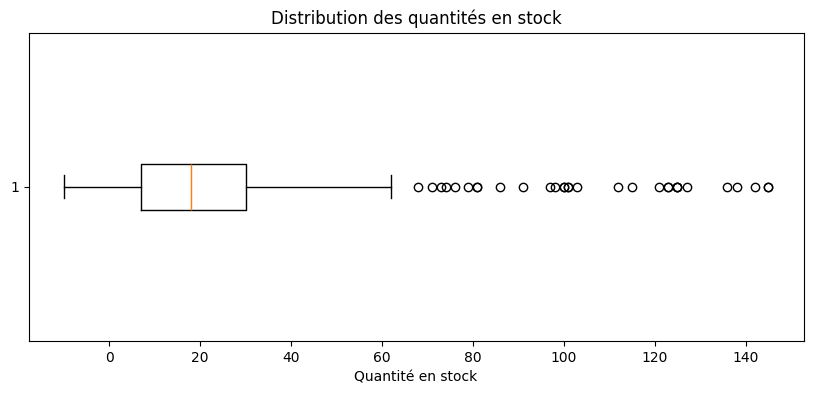

In [ ]:
plt.figure(figsize=(10, 4))

plt.boxplot(df_erp["stock_quantity"].dropna(), vert=False)

plt.title("Distribution des quantités en stock")
plt.xlabel("Quantité en stock")

plt.show()

### Produits avec les niveaux de stock les plus élevés

Afin de compléter la distribution globale du stock, ce graphique met en évidence les produits ayant les niveaux de stock les plus importants.  
Il permet d’identifier rapidement les références qui immobilisent le plus de stock.


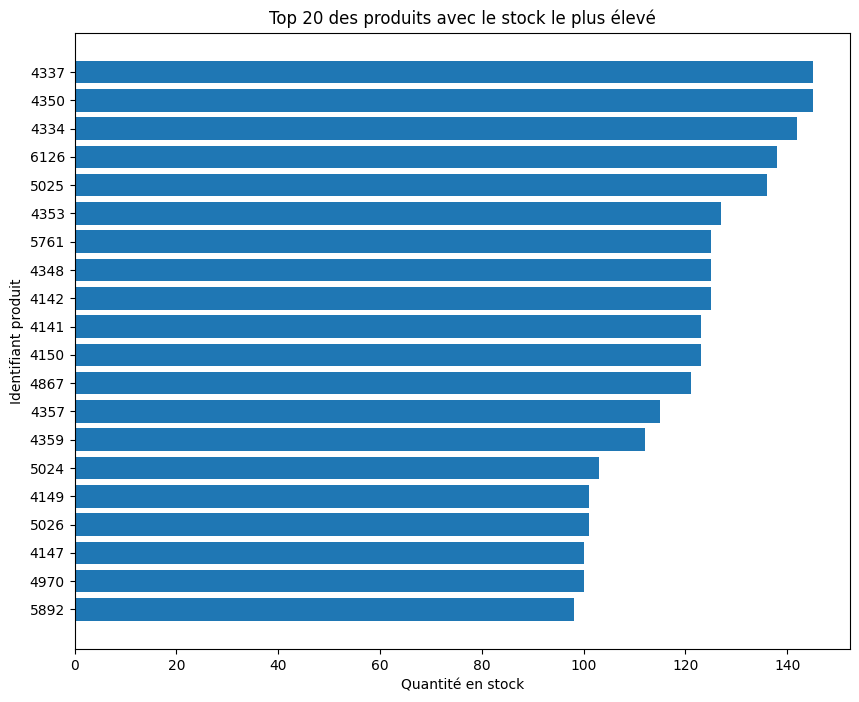

In [ ]:
# Visualiser les produits ayant les stocks les plus élevés

top_stock = df_erp.sort_values("stock_quantity", ascending=False).head(TOP_N)

plt.figure(figsize=(10, 8))
plt.barh(top_stock["product_id"].astype(str), top_stock["stock_quantity"])

plt.title(f"Top {TOP_N} des produits avec le stock le plus élevé")
plt.xlabel("Quantité en stock")
plt.ylabel("Identifiant produit")

plt.gca().invert_yaxis()
plt.show()


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1 - Analyse exploratoire de chaque variable du fichier erp.xlsx</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.1 - Analyse de la variable PRIX</h3>
</div>

In [ ]:
###############
## LES PRIX  ##
###############

print("Nombre d’articles avec un prix non renseigné :", df_erp["price"].isnull().sum())
print("Nombre d’articles avec un prix non renseigné : {}".format(df_erp["price"].isnull().sum())) 
display(df_erp["price"].min())
display(df_erp["price"].max())
display(df_erp[df_erp["price"] < 0])

Nombre d’articles avec un prix non renseigné : 0
Nombre d’articles avec un prix non renseigné : 0


np.float64(-20.0)

np.float64(225.0)

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2,verification_stock_status
151,4233,0,-20.0,0,outofstock,10.33,outofstock,True
469,5017,0,-8.0,0,outofstock,4.34,outofstock,True
739,6594,0,-9.1,19,instock,4.61,instock,True


### Analyse des prix négatifs

Le contrôle de la variable `price` permet de vérifier la présence éventuelle de prix manquants ou négatifs.

Un prix de vente négatif est une anomalie métier, car un produit ne peut pas être vendu avec un prix inférieur à zéro.

Les lignes affichées par le code doivent être analysées avant correction. Ces valeurs peuvent provenir d’une erreur de saisie du signe négatif.

In [ ]:
nb_prix_negatifs = df_erp[df_erp["price"] < 0].shape[0]

print("Nombre de prix négatifs :", nb_prix_negatifs)

Nombre de prix négatifs : 3


In [ ]:
# Correction des prix négatifs en conservant leur valeur absolue

df_erp.loc[df_erp["price"] < 0, "price"] = df_erp.loc[df_erp["price"] < 0, "price"].abs()

In [ ]:
# Vérifier qu'il n'y a plus de prix négatif

display(df_erp[df_erp["price"] < 0])

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2,verification_stock_status


In [ ]:
print("Prix minimum après correction :", df_erp["price"].min())

Prix minimum après correction : 5.2


### Correction des prix négatifs

Les prix négatifs détectés dans le fichier ERP sont corrigés en conservant leur valeur absolue.

Un prix négatif est une anomalie métier, car un produit ne peut pas être vendu avec un prix inférieur à zéro.

Après correction, un contrôle est réalisé sur le prix minimum afin de vérifier qu’il ne reste plus de valeur négative dans la colonne `price`.

Cette anomalie doit être signalée comme une probable erreur de saisie dans le système ERP.

Une représentation graphique complémentaire, comme un boxplot, permet ensuite de contrôler la distribution des prix.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.2 - Analyse de la variable STOCK</h3>
</div>

In [ ]:
#######################
### stock_quantity  ###
#######################

print("Stock minimum :", df_erp["stock_quantity"].min())
print("Stock maximum :", df_erp["stock_quantity"].max())
#Afficher les stocks inférieurs à 0 (qu'est-ce qu'il faut en faire ?) 
# Les stocks inférieurs à 0 sont des anomalies, car un stock ne peut pas être négatif dans un système réel. 
# Cela peut provenir d’erreurs de saisie, de problèmes de synchronisation ou d’un décalage entre les ventes et les mises à jour du stock.
# Ces lignes doivent être analysées, puis soit corrigées, soit exclues du jeu de données si aucune correction fiable n’est possible.
display(df_erp[df_erp["stock_quantity"] < 0])

Stock minimum : -10
Stock maximum : 145


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2,verification_stock_status
449,4973,0,10.0,-10,outofstock,4.96,outofstock,True
573,5700,1,44.5,-1,outofstock,22.30,outofstock,True


### Analyse des stocks négatifs

Le contrôle de la colonne `stock_quantity` permet d’identifier les éventuels stocks négatifs.

Un stock négatif est une anomalie métier, car une quantité en stock ne devrait pas être inférieure à zéro.

Les lignes affichées doivent être analysées, car elles peuvent provenir d’une erreur de saisie, d’un problème de synchronisation entre les ventes et les mises à jour de stock, ou d’un décalage dans l’extraction des données.

In [ ]:
# Compter le nombre de stocks négatifs

nb_stocks_negatifs = df_erp[df_erp["stock_quantity"] < 0].shape[0]

print("Nombre de stocks négatifs :", nb_stocks_negatifs)

Nombre de stocks négatifs : 2


In [ ]:
# Correction des stocks négatifs en les remplaçant par 0

df_erp.loc[df_erp["stock_quantity"] < 0, "stock_quantity"] = 0

In [ ]:
print("Stock minimum après correction :", df_erp["stock_quantity"].min())

Stock minimum après correction : 0


In [ ]:
# Recalculer le statut théorique après correction des stocks

df_erp["stock_status_2"] = df_erp["stock_quantity"].apply(
    lambda x: "outofstock" if x <= 0 else "instock"
)

In [ ]:
# Mettre à jour le statut de stock après correction

df_erp["stock_status"] = df_erp["stock_status_2"]

In [ ]:
# Vérifier qu'il n'y a plus de stock négatif après correction

display(df_erp[df_erp["stock_quantity"] < 0])

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2,verification_stock_status


In [ ]:
# Vérifier que le statut de stock est toujours cohérent après correction

display((df_erp["stock_status"] == df_erp["stock_status_2"]).sum())

np.int64(825)

### Correction des stocks négatifs

Les stocks négatifs détectés sont corrigés en les remplaçant par `0`, car il n’est pas possible de déduire automatiquement la vraie quantité en stock.

Après correction, un contrôle est réalisé sur le stock minimum afin de vérifier qu’il ne reste plus de valeur négative.

Le statut de stock est ensuite recalculé afin de rester cohérent avec la quantité en stock corrigée.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.3 - Analyse de la variable ONSALE_WEB</h3>
</div>

In [ ]:
# Vérification de la colonne onsale_web et des valeurs qu'elle contient. Que signifient-elles?
# La variable `onsale_web` est une variable binaire indiquant si un produit est disponible à la vente sur le site web. 
# La valeur 1 correspond à un produit en ligne, tandis que la valeur 0 indique qu’il n’est pas disponible.
display(df_erp["onsale_web"].unique())
display(df_erp["onsale_web"].value_counts())

array([1, 0])

onsale_web
1    716
0    109
Name: count, dtype: int64

In [ ]:
# Quelles sont les colonnes à conserver selon vous?
# Les colonnes conservées sont celles utiles à l’analyse métier, 
# notamment l’identifiant produit, le prix, le stock, le statut de stock, le prix d’achat et la disponibilité web.
display(df_erp.columns)

Index(['product_id', 'onsale_web', 'price', 'stock_quantity', 'stock_status',
       'purchase_price', 'stock_status_2', 'verification_stock_status'],
      dtype='object')

In [ ]:
# Supprimer la colonne comportant le libellé "stock_status_2" car elle est redondante 
# avec la colonne "stock_status".
# La colonne stock_status_2 a été supprimée car elle est redondante avec la colonne stock_status après vérification de leur cohérence.
df_erp = df_erp.drop(columns=["stock_status_2"],  errors="ignore")

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.4 - Analyse de la variable prix d'achat</h3>
</div>

In [ ]:
######################
##   prix d'achat   ##
######################

# Vérification de la colonne purchase_price : 
# Afficher le ou les prix non renseignés dans la colonne "purchase_price"
print("Nombre de prix d'achat non renseignés :", df_erp["purchase_price"].isnull().sum())
print("Prix d'achat minimum :", df_erp["purchase_price"].min())
print("Prix d'achat maximum :", df_erp["purchase_price"].max())

Nombre de prix d'achat non renseignés : 0
Prix d'achat minimum : 2.74
Prix d'achat maximum : 137.81


### Analyse du prix d'achat

La colonne `purchase_price` correspond au prix d'achat des produits.

Le contrôle précédent permet de vérifier la présence éventuelle de valeurs manquantes, nulles ou négatives dans cette colonne.

Cette variable est importante pour la suite de l'analyse, car elle sera utilisée pour calculer la marge et le taux de marge.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier web.xlsx</h3>
</div>
 

In [ ]:
print("Nombre de lignes :", df_web.shape[0])
print("Nombre de colonnes :", df_web.shape[1])

df_web.info()

Nombre de lignes : 1513
Nombre de colonnes : 29
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sku                    1428 non-null   object        
 1   virtual                1513 non-null   int64         
 2   downloadable           1513 non-null   int64         
 3   rating_count           1513 non-null   int64         
 4   average_rating         1430 non-null   float64       
 5   total_sales            1430 non-null   float64       
 6   tax_status             716 non-null    object        
 7   tax_class              0 non-null      float64       
 8   post_author            1430 non-null   float64       
 9   post_date              1430 non-null   datetime64[ns]
 10  post_date_gmt          1430 non-null   datetime64[ns]
 11  post_content           0 non-null      float64       
 12  product_type  

In [ ]:
# Compter les valeurs manquantes par colonne

display(df_web.isnull().sum().sort_values(ascending=False))

tax_class                1513
post_content             1513
post_password            1513
post_content_filtered    1513
post_mime_type            799
post_excerpt              797
tax_status                797
sku                        85
product_type               84
post_author                83
total_sales                83
post_date_gmt              83
average_rating             83
post_modified              83
post_name                  83
post_parent                83
post_date                  83
comment_status             83
ping_status                83
post_status                83
post_title                 83
guid                       83
menu_order                 83
post_type                  83
post_modified_gmt          83
comment_count              83
downloadable                0
rating_count                0
virtual                     0
dtype: int64

### Visualisation des valeurs manquantes du fichier web

En complément du contrôle numérique, ce graphique affiche uniquement les colonnes contenant des valeurs manquantes.  
Il permet d’identifier rapidement les champs les plus incomplets et de prioriser les contrôles qualité.


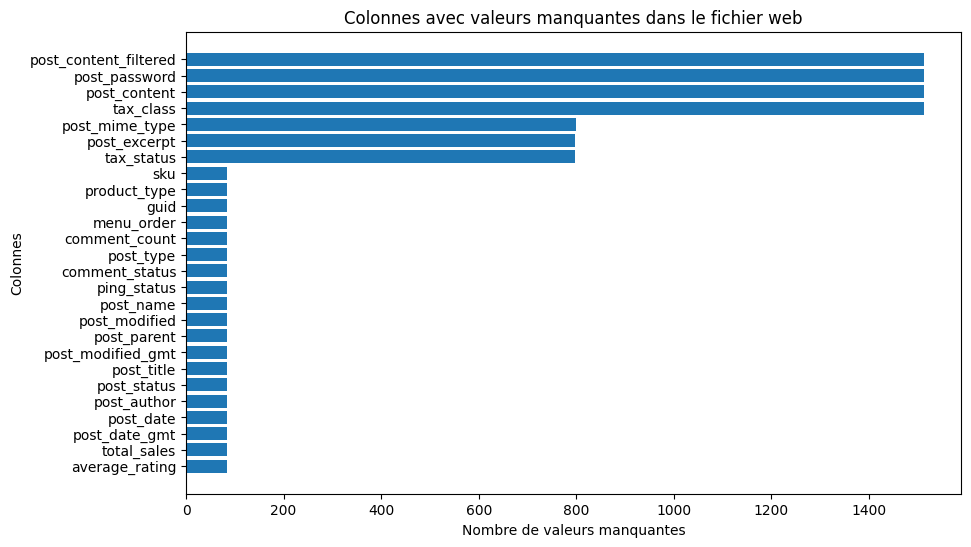

In [ ]:
# Visualiser les colonnes du fichier web contenant des valeurs manquantes

valeurs_manquantes_web = df_web.isnull().sum().sort_values(ascending=True)
valeurs_manquantes_web = valeurs_manquantes_web[valeurs_manquantes_web > 0]

if valeurs_manquantes_web.empty:
    print("Aucune valeur manquante détectée dans le fichier web.")
else:
    plt.figure(figsize=(10, 6))
    plt.barh(valeurs_manquantes_web.index, valeurs_manquantes_web.values)

    plt.title("Colonnes avec valeurs manquantes dans le fichier web")
    plt.xlabel("Nombre de valeurs manquantes")
    plt.ylabel("Colonnes")

    plt.show()


In [ ]:
#Consulter le nombre de colonnes
display(df_web.shape[1])
#La nature des données dans chacune des colonnes
display(df_web.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
display(df_web.count())

29

sku                              object
virtual                           int64
downloadable                      int64
rating_count                      int64
average_rating                  float64
total_sales                     float64
tax_status                       object
tax_class                       float64
post_author                     float64
post_date                datetime64[ns]
post_date_gmt            datetime64[ns]
post_content                    float64
product_type                     object
post_title                       object
post_excerpt                     object
post_status                      object
comment_status                   object
ping_status                      object
post_password                   float64
post_name                        object
post_modified            datetime64[ns]
post_modified_gmt        datetime64[ns]
post_content_filtered           float64
post_parent                     float64
guid                             object


sku                      1428
virtual                  1513
downloadable             1513
rating_count             1513
average_rating           1430
total_sales              1430
tax_status                716
tax_class                   0
post_author              1430
post_date                1430
post_date_gmt            1430
post_content                0
product_type             1429
post_title               1430
post_excerpt              716
post_status              1430
comment_status           1430
ping_status              1430
post_password               0
post_name                1430
post_modified            1430
post_modified_gmt        1430
post_content_filtered       0
post_parent              1430
guid                     1430
menu_order               1430
post_type                1430
post_mime_type            714
comment_count            1430
dtype: int64

### Résumé statistique du fichier web

La méthode `.describe(include="all")` permet d'obtenir un résumé des colonnes du fichier web.

Pour les variables numériques, elle affiche des indicateurs comme la moyenne, le minimum, le maximum et les quartiles.

Pour les variables textuelles, elle affiche notamment le nombre de valeurs uniques, la valeur la plus fréquente et sa fréquence.

Cette étape permet d'avoir une première vision globale des données avant de poursuivre les contrôles qualité.

In [ ]:
# Afficher les colonnes actuellement présentes dans df_web

display(df_web.columns.tolist())

['sku',
 'virtual',
 'downloadable',
 'rating_count',
 'average_rating',
 'total_sales',
 'tax_status',
 'tax_class',
 'post_author',
 'post_date',
 'post_date_gmt',
 'post_content',
 'product_type',
 'post_title',
 'post_excerpt',
 'post_status',
 'comment_status',
 'ping_status',
 'post_password',
 'post_name',
 'post_modified',
 'post_modified_gmt',
 'post_content_filtered',
 'post_parent',
 'guid',
 'menu_order',
 'post_type',
 'post_mime_type',
 'comment_count']

In [ ]:
# Vérifier les types de lignes présentes dans le fichier web

display(df_web["post_type"].value_counts(dropna=False))

post_type
product       716
attachment    714
NaN            83
Name: count, dtype: int64

### Visualisation de la répartition des types de contenus web

En complément du comptage des valeurs, je représente graphiquement la répartition des types de contenus présents dans le fichier web.  
Cette visualisation permet de vérifier rapidement la proportion entre les produits réellement exploitables pour l’analyse commerciale et les autres types de contenus.


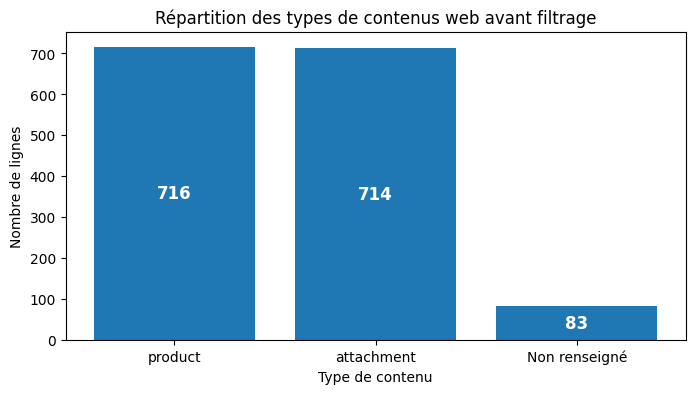

In [ ]:
# Visualiser la répartition des types de contenus présents dans le fichier web brut

post_type_counts = df_web_brut["post_type"].value_counts(dropna=False)

post_type_labels = [
    "Non renseigné" if pd.isna(label) else str(label)
    for label in post_type_counts.index
]

plt.figure(figsize=(8, 4))

bars = plt.bar(post_type_labels, post_type_counts.values)

plt.title("Répartition des types de contenus web avant filtrage")
plt.xlabel("Type de contenu")
plt.ylabel("Nombre de lignes")

# Ajouter les chiffres dans les barres
for bar in bars:
    hauteur = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        hauteur / 2,
        f"{int(hauteur)}",
        ha="center",
        va="center",
        color="white",
        fontsize=12,
        fontweight="bold"
    )

plt.show()

### Analyse de la colonne post_type

La colonne `post_type` permet d'identifier la nature des lignes présentes dans le fichier web.

Le contrôle précédent affiche la répartition des types de lignes : produits, pièces jointes ou valeurs manquantes.

Pour l'analyse commerciale, seules les lignes de type `product` doivent être conservées, car les lignes `attachment` ne représentent pas des ventes de produits.

In [ ]:
# Conserver uniquement les lignes correspondant à de vrais produits

df_web = df_web[df_web["post_type"] == "product"].copy()

print("Nombre de lignes après filtrage :", df_web.shape[0])
print("Nombre de colonnes après filtrage :", df_web.shape[1])

Nombre de lignes après filtrage : 716
Nombre de colonnes après filtrage : 29


In [ ]:
# Vérifier si la colonne sku contient encore des doublons après filtrage

nb_doublons_sku = df_web["sku"].duplicated().sum()

print("Nombre de doublons dans sku :", nb_doublons_sku)

Nombre de doublons dans sku : 1


In [ ]:
# Afficher les lignes concernées par un doublon de SKU

display(df_web[df_web["sku"].duplicated(keep=False)].sort_values("sku"))

,sku,virtual,downloadable,rating_count,average_rating,total_sales,tax_status,tax_class,post_author,post_date,post_date_gmt,post_content,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_password,post_name,post_modified,post_modified_gmt,post_content_filtered,post_parent,guid,menu_order,post_type,post_mime_type,comment_count
1084,NaN,0,0,0,0.0,-56.0,taxable,NaN,2.0,2018-08-08 11:23:43,2018-08-08 09:23:43,NaN,Vin,Pierre Jean Villa Condrieu Jardin Suspendu 2018,"<span id=""u1194-83"">Le nez séduit par ses parfums de fruit blancs pochés et de verveine. Délicate, juste et maîtrisée, sa longueur est saisissant</span><span id=""u1194-84"">e</span>.",publish,closed,closed,NaN,pierre-jean-villa-condrieu-suspendu-2018,2019-11-02 13:24:01,2019-11-02 12:24:01,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&#038;p=5075,0.0,product,NaN,0.0
1087,NaN,0,0,0,0.0,-17.0,taxable,NaN,2.0,2018-07-31 12:07:23,2018-07-31 10:07:23,NaN,Vin,Pierre Jean Villa Côte Rôtie Fongeant 2017,"Fongeant 2017 explose sur un fruit brillant, préserve par un élevage fin. C'est la démonstration qu'une cuvée bâtie pour la garde peut exprimer de la finesse dès sa jeunesse.",publish,closed,closed,NaN,pierre-jean-villa-cote-rotie-fongeant-2017,2019-11-02 13:24:15,2019-11-02 12:24:15,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&#038;p=5070,0.0,product,NaN,0.0


In [ ]:
# Afficher le doublon de SKU avec uniquement les colonnes utiles

df_doublon_sku = df_web.loc[
    df_web["sku"].duplicated(keep=False),
    ["sku", "post_title", "total_sales", "post_name", "guid", "post_type"]
].sort_values("sku")

display(df_doublon_sku)


,sku,post_title,total_sales,post_name,guid,post_type
1084,NaN,Pierre Jean Villa Condrieu Jardin Suspendu 2018,-56.0,pierre-jean-villa-condrieu-suspendu-2018,https://www.bottle-neck.fr/?post_type=product&#038;p=5075,product
1087,NaN,Pierre Jean Villa Côte Rôtie Fongeant 2017,-17.0,pierre-jean-villa-cote-rotie-fongeant-2017,https://www.bottle-neck.fr/?post_type=product&#038;p=5070,product


In [ ]:
# Identifier les produits sans SKU

df_web_sans_sku = df_web.loc[
    df_web["sku"].isnull(),
    ["sku", "post_title", "total_sales", "post_name", "guid", "post_type"]
]

print("Nombre de produits sans SKU :", df_web_sans_sku.shape[0])

display(df_web_sans_sku)


Nombre de produits sans SKU : 2


,sku,post_title,total_sales,post_name,guid,post_type
1084,NaN,Pierre Jean Villa Condrieu Jardin Suspendu 2018,-56.0,pierre-jean-villa-condrieu-suspendu-2018,https://www.bottle-neck.fr/?post_type=product&#038;p=5075,product
1087,NaN,Pierre Jean Villa Côte Rôtie Fongeant 2017,-17.0,pierre-jean-villa-cote-rotie-fongeant-2017,https://www.bottle-neck.fr/?post_type=product&#038;p=5070,product


### Analyse des produits sans SKU

Après avoir conservé uniquement les lignes de type `product`, le contrôle précédent permet d’identifier les éventuels produits sans SKU.

Le SKU est indispensable pour faire le lien entre le fichier web, la table de liaison et le fichier ERP.

Les lignes sans SKU constituent donc une anomalie de qualité des données : sans identifiant web, elles ne pourront pas être rapprochées correctement avec les autres fichiers.

Ces produits devront être corrigés dans le système source ou exclus temporairement des jointures.

In [ ]:
# Vérifier les doublons SKU uniquement sur les lignes où le SKU est renseigné

df_web_avec_sku = df_web[df_web["sku"].notnull()].copy()

nb_doublons_sku = df_web_avec_sku["sku"].duplicated().sum()

print("Nombre de vrais doublons dans sku :", nb_doublons_sku)

Nombre de vrais doublons dans sku : 0


In [ ]:
# Supprimer les produits sans SKU car ils ne pourront pas être utilisés pour la jointure

df_web = df_web[df_web["sku"].notnull()].copy()

print("Nombre de lignes après suppression des produits sans SKU :", df_web.shape[0])

Nombre de lignes après suppression des produits sans SKU : 714


### Selon vous, quelles sont les colonnes à conserver ?

Choix des colonnes à conserver

Pour la suite de l’analyse, toutes les colonnes du fichier web ne sont pas nécessaires.

Les colonnes à conserver sont celles qui apportent une information utile pour l’analyse métier et pour la future jointure avec les autres fichiers :

- `sku` : identifiant produit côté web, indispensable pour faire le lien avec la table de liaison ;
- `total_sales` : nombre de ventes réalisées sur le site web ;
- `average_rating` : note moyenne du produit ;
- `rating_count` : nombre d’avis clients ;
- `post_title` : nom du produit ;
- `post_type` : permet de vérifier que l’on conserve uniquement les lignes correspondant à de vrais produits ;
- `post_name` et `guid` : utiles temporairement pour identifier les produits en cas d’anomalie, notamment les produits sans SKU.

Les autres colonnes sont principalement des métadonnées techniques issues de WordPress et ne sont pas nécessaires pour l’analyse commerciale.

In [ ]:
# Si vous avez défini des colonnes à supprimer, effectuer l'opération
# Les colonnes conservées sont celles utiles à l’analyse métier, notamment l’identifiant produit (SKU),
# les ventes (total_sales), les informations de notation (average_rating, rating_count) et le titre du produit (post_title).
# Les autres colonnes, principalement techniques, ont été écartées car non pertinentes pour l’analyse.
# Les autres colonnes sont principalement des métadonnées techniques issues de WordPress et n’apportent pas de valeur pour l’analyse business.
df_web = df_web[[
    "sku",
    "total_sales",
    "average_rating",
    "rating_count",
    "post_title",
    "post_type",
    "post_name",
    "guid"
]].copy()

In [ ]:
# Vérifier les colonnes conservées

display(df_web.columns.tolist())

['sku',
 'total_sales',
 'average_rating',
 'rating_count',
 'post_title',
 'post_type',
 'post_name',
 'guid']

In [ ]:
# Visualisation des valeurs de la colonne sku
# Quelles sont les valeurs qui ne semblent pas respecter la régle de codification?

print("Nombre de lignes :", df_web.shape[0])
print("Nombre de SKU renseignés :", df_web["sku"].notnull().sum())
print("Nombre de SKU manquants :", df_web["sku"].isnull().sum())
print("Nombre de SKU uniques :", df_web["sku"].nunique())

Nombre de lignes : 714
Nombre de SKU renseignés : 714
Nombre de SKU manquants : 0
Nombre de SKU uniques : 714


In [ ]:
# Identifier les SKU qui ne respectent pas une codification numérique

sku_numerique = pd.to_numeric(df_web["sku"], errors="coerce")

df_sku_atypiques = df_web.loc[
    sku_numerique.isnull(),
    ["sku", "post_title", "total_sales", "average_rating", "rating_count"]
]

display(df_sku_atypiques)

,sku,post_title,total_sales,average_rating,rating_count
272,13127-1,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,4.0,0.0,0
1387,bon-cadeau-25-euros,Bon cadeau de 25€,7.0,0.0,0


### Analyse des SKU ne respectant pas la codification

La majorité des SKU du fichier web suivent une codification numérique.

Le contrôle précédent permet d’identifier les éventuelles valeurs atypiques, c’est-à-dire les SKU qui ne peuvent pas être convertis en valeur numérique.

Ces valeurs ne sont pas supprimées automatiquement, car elles peuvent correspondre à des produits spécifiques ou à des variantes.

Elles devront toutefois être surveillées lors de la jointure avec la table de liaison.

In [ ]:
# Si vous avez identifié des codes articles ne respectant pas la régle de codification, consultez-les
# Deux valeurs atypiques ont été identifiées dans la colonne SKU : '13127-1' et 'bon-cadeau-25-euros'.
# Elles ne respectent pas la structure numérique observée pour la majorité des produits.
# '13127-1' semble correspondre à une variante produit, tandis que 'bon-cadeau-25-euros'
# correspond probablement à un produit spécifique de type carte cadeau.
# Ces valeurs doivent être traitées à part car elles peuvent perturber la jointure avec l’ERP.

display(df_web[df_web["sku"].isin(["13127-1", "bon-cadeau-25-euros"])])

,sku,total_sales,average_rating,rating_count,post_title,post_type,post_name,guid
272,13127-1,4.0,0.0,0,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,product,clos-du-mont-olivet-chateauneuf-du-pape-2007-2,https://www.bottle-neck.fr/?post_type=product&#038;p=7247
1387,bon-cadeau-25-euros,7.0,0.0,0,Bon cadeau de 25€,product,bon-cadeau-de-25-euros,https://www.bottle-neck.fr/?post_type=product&#038;p=4954


### Analyse des SKU atypiques

Les SKU atypiques affichés dans la cellule précédente ne respectent pas la codification numérique majoritaire observée dans le fichier web.

Ces valeurs ne sont pas supprimées si elles sont renseignées, uniques et associées à des produits réels.

Elles devront cependant être surveillées lors de la jointure avec la table de liaison, car elles doivent être comparées comme du texte et non comme des valeurs numériques.

In [ ]:
# Vérification finale de la colonne sku après nettoyage

print("Nombre de lignes :", df_web.shape[0])
print("Nombre de SKU renseignés :", df_web["sku"].notnull().sum())
print("Nombre de SKU manquants :", df_web["sku"].isnull().sum())
print("Nombre de SKU uniques :", df_web["sku"].nunique())
print("Nombre de doublons SKU :", df_web["sku"].duplicated().sum())

Nombre de lignes : 714
Nombre de SKU renseignés : 714
Nombre de SKU manquants : 0
Nombre de SKU uniques : 714
Nombre de doublons SKU : 0


In [ ]:
# Vérifier qu'il ne reste plus de lignes sans SKU après nettoyage
display(df_web[df_web["sku"].isnull()])

,sku,total_sales,average_rating,rating_count,post_title,post_type,post_name,guid


### Vérification finale des SKU manquants

Après nettoyage du fichier web, je vérifie automatiquement le nombre de SKU renseignés, manquants, uniques et dupliqués.

Ce contrôle permet de confirmer si le fichier web est prêt à être utilisé pour les futures jointures avec la table de liaison et le fichier ERP.

In [ ]:
# Pour les codes articles identifiés, réaliser une analyse et définir l'action à entreprendre
# Les lignes sans code article ne contiennent pas d’information exploitable pour la jointure avec les autres sources de données.
# Elles doivent donc être supprimées afin de garantir la qualité de l’analyse.
df_web = df_web[df_web["sku"].notnull()]

In [ ]:
# La clé pour chaque ligne est-elle unique? autrement dit, y a-t-il des doublons?
# La vérification de l’unicité des SKU permet de s’assurer qu’il n’existe pas de doublons pouvant fausser les analyses.
display(df_web["sku"].duplicated().sum())
display(df_web[df_web["sku"].duplicated(keep=False)])

np.int64(0)

,sku,total_sales,average_rating,rating_count,post_title,post_type,post_name,guid


In [ ]:
# Les lignes sans code article semblent être toutes non renseignées
# Pour s'en assurer, réaliser les étapes suivantes:
#1 - Créer un dataframe avec uniquement les lignes sans code article
# Un sous-ensemble des lignes sans SKU a été analysé afin de vérifier si ces données contiennent des informations exploitables.
df_sans_sku = df_web[df_web["sku"].isnull()]
#2 - Utiliser la fonction df.info() sur ce nouveau dataframe pour observer le nombre de valeurs renseignées dans chacune des colonnes
df_sans_sku.info()
#3 - Que constatez-vous?
# L’analyse montre que les lignes sans SKU sont majoritairement vides ou peu exploitables, ce qui confirme leur suppression du dataset.

<class 'pandas.core.frame.DataFrame'>
Index: 0 entries
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sku             0 non-null      object 
 1   total_sales     0 non-null      float64
 2   average_rating  0 non-null      float64
 3   rating_count    0 non-null      int64  
 4   post_title      0 non-null      object 
 5   post_type       0 non-null      object 
 6   post_name       0 non-null      object 
 7   guid            0 non-null      object 
dtypes: float64(2), int64(1), object(5)
memory usage: 0.0+ bytes


### Constat sur les lignes sans SKU

Après nettoyage, je contrôle le dataframe `df_sans_sku` afin de vérifier s’il reste des lignes sans code article.

Les lignes sans code article ne peuvent pas être utilisées pour la jointure avec la table de liaison et le fichier ERP.

Si le contrôle affiche encore des lignes, elles doivent être analysées ou exclues temporairement de la jointure.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Analyse exploratoire du fichier liaison.xlsx</h3>
</div>

In [ ]:
# Dimension du dataset
print("Dimension du dataset :", df_liaison.shape)
print("Nombre d'observations :", df_liaison.shape[0])
print("Nombre de caractéristiques :", df_liaison.shape[1])

Dimension du dataset : (825, 2)
Nombre d'observations : 825
Nombre de caractéristiques : 2


In [ ]:
print("Nombre de colonnes :", df_liaison.shape[1])

# Afficher la nature des données et le nombre de valeurs présentes dans chaque colonne
df_liaison.info()


Nombre de colonnes : 2
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      734 non-null    object
 1   product_id  825 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 13.0+ KB


### Analyse générale du fichier liaison

Le fichier `liaison.xlsx` contient les colonnes `id_web` et `product_id`.

La colonne `product_id` permet d’identifier les produits issus de l’ERP.

La colonne `id_web` permet de faire le lien avec les références du fichier web.

Les contrôles précédents permettent de vérifier automatiquement le volume du fichier, le nombre de valeurs renseignées et les éventuelles valeurs manquantes. Ces éléments devront être analysés avant les jointures, car ils peuvent empêcher le rapprochement complet entre l’ERP et le fichier web.

In [ ]:
#Les valeurs de la colonne "product_id" sont-elles toutes uniques?

print("Nombre total de lignes :", df_liaison.shape[0])
print("Nombre de product_id uniques :", df_liaison["product_id"].nunique())
print("Nombre de doublons product_id :", df_liaison["product_id"].duplicated().sum())

# Afficher les éventuels doublons
display(df_liaison[df_liaison["product_id"].duplicated(keep=False)])

Nombre total de lignes : 825
Nombre de product_id uniques : 825
Nombre de doublons product_id : 0


,id_web,product_id


### Unicité de la colonne product_id

Le contrôle précédent vérifie si la colonne `product_id` contient uniquement des valeurs uniques.

Si aucun doublon n’est détecté, la colonne `product_id` peut être considérée comme une clé fiable dans la table de liaison pour faire le rapprochement avec le fichier ERP.

Si des doublons apparaissent, ils devront être analysés avant la jointure.

In [ ]:
# Les valeurs de la colonne "id_web" sont-elles toutes uniques ?

print("Nombre total de lignes :", df_liaison.shape[0])
print("Nombre de id_web renseignés :", df_liaison["id_web"].notnull().sum())
print("Nombre de id_web manquants :", df_liaison["id_web"].isnull().sum())
print("Nombre de id_web uniques renseignés :", df_liaison["id_web"].dropna().nunique())

# Vérifier les vrais doublons uniquement parmi les id_web renseignés
df_id_web_renseignes = df_liaison[df_liaison["id_web"].notnull()]

print("Nombre de vrais doublons id_web :", df_id_web_renseignes["id_web"].duplicated().sum())

# Afficher les vrais doublons éventuels
display(df_id_web_renseignes[df_id_web_renseignes["id_web"].duplicated(keep=False)])

Nombre total de lignes : 825
Nombre de id_web renseignés : 734
Nombre de id_web manquants : 91
Nombre de id_web uniques renseignés : 734
Nombre de vrais doublons id_web : 0


,id_web,product_id


### Unicité de la colonne id_web

Le contrôle précédent vérifie le nombre de valeurs `id_web` renseignées, manquantes et uniques.

La colonne `id_web` doit être surveillée car elle sert au rapprochement avec le fichier web.

Les valeurs manquantes peuvent empêcher certains produits ERP d’être rapprochés avec les données web. Les doublons doivent également être analysés uniquement parmi les valeurs renseignées.

In [ ]:
# Avons-nous des articles sans correspondance?
# Identifier les articles sans correspondance web

df_liaison_sans_correspondance = df_liaison[df_liaison["id_web"].isnull()]

print("Nombre d'articles sans correspondance web :", df_liaison_sans_correspondance.shape[0])

display(df_liaison_sans_correspondance.count())

Nombre d'articles sans correspondance web : 91


id_web         0
product_id    91
dtype: int64

### Articles sans correspondance web

La cellule précédente identifie les lignes de la table de liaison pour lesquelles la colonne `id_web` est manquante.

Ces produits ne pourront pas être rapprochés directement avec les données issues du fichier `web.xlsx`.

Cette situation peut correspondre à des produits non vendus en ligne, à des références non encore créées sur le site web, ou à un problème de mise à jour de la table de liaison.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jointures des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jointure des fichiers df_erp et df_liaison</h3>
</div>

In [ ]:
# Jointures des datasets df_erp et df_liaison

df_merge = df_erp.merge(
    df_liaison,
    on="product_id",
    how="left",
    indicator="merge_erp_liaison"
)

print("Nombre de lignes dans df_erp :", df_erp.shape[0])
print("Nombre de lignes dans df_liaison :", df_liaison.shape[0])
print("Nombre de lignes après jointure :", df_merge.shape[0])

display(df_merge.head())

Nombre de lignes dans df_erp : 825
Nombre de lignes dans df_liaison : 825
Nombre de lignes après jointure : 825


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,verification_stock_status,id_web,merge_erp_liaison
0,3847,1,24.2,16,instock,12.88,True,15298,both
1,3849,1,34.3,10,instock,17.54,True,15296,both
2,3850,1,20.8,0,outofstock,10.64,True,15300,both
3,4032,1,14.1,26,instock,6.92,True,19814,both
4,4039,1,46.0,3,instock,23.77,False,19815,both


### Jointures entre le fichier ERP et la table de liaison

La jointure entre `df_erp` et `df_liaison` a été réalisée à partir de la colonne commune `product_id`.

Les volumes avant et après jointure sont calculés automatiquement dans la cellule de code afin de vérifier si la jointure conserve bien les lignes attendues.

La colonne `merge_erp_liaison` permet de contrôler l’origine des lignes après la jointure et d’identifier d’éventuelles lignes non rapprochées.

In [ ]:
# Y a t-il des lignes ne "matchant" pas entre les 2 fichiers?

print("Répartition des correspondances :")
print(df_merge["merge_erp_liaison"].value_counts())

# Afficher les lignes qui ne sont pas présentes dans les deux fichiers
display(df_merge[df_merge["merge_erp_liaison"] != "both"])

Répartition des correspondances :
merge_erp_liaison
both          825
left_only       0
right_only      0
Name: count, dtype: int64


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,verification_stock_status,id_web,merge_erp_liaison


### Vérification des correspondances entre ERP et liaison

La répartition de la colonne `merge_erp_liaison` permet de vérifier si les lignes sont présentes dans les deux fichiers ou seulement dans l’un des deux.

Si aucune ligne ne ressort en `left_only` ou `right_only`, cela indique que les produits ERP ont bien une ligne correspondante dans la table de liaison via la clé `product_id`.

Certaines lignes peuvent toutefois encore avoir un `id_web` manquant. Ces cas ne sont pas des erreurs de correspondance entre ERP et liaison, mais ils pourront empêcher la future jointure avec le fichier web.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jointure des fichiers df_merge et df_web</h3>
</div>

In [ ]:
# Conversion des identifiants en texte pour éviter les problèmes de type lors de la jointure
df_merge["id_web"] = df_merge["id_web"].astype(str)
df_web["sku"] = df_web["sku"].astype(str)

# Remplacer les valeurs "nan" issues de la conversion en véritables valeurs manquantes
df_merge.loc[df_merge["id_web"] == "nan", "id_web"] = None

# Jointures des datasets df_merge et df_web
df_final = df_merge.merge(
    df_web,
    left_on="id_web",
    right_on="sku",
    how="left",
    indicator="merge_web"
)

print("Nombre de lignes dans df_merge :", df_merge.shape[0])
print("Nombre de lignes dans df_web :", df_web.shape[0])
print("Nombre de lignes après jointure :", df_final.shape[0])

display(df_final.head())

Nombre de lignes dans df_merge : 825
Nombre de lignes dans df_web : 714
Nombre de lignes après jointure : 825


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,verification_stock_status,id_web,merge_erp_liaison,sku,total_sales,average_rating,rating_count,post_title,post_type,post_name,guid,merge_web
0,3847,1,24.2,16,instock,12.88,True,15298,both,15298,6.0,0.0,0.0,Pierre Jean Villa Saint-Joseph Préface 2018,product,pierre-jean-villa-saint-joseph-preface-2018,https://www.bottle-neck.fr/?post_type=product&#038;p=3847,both
1,3849,1,34.3,10,instock,17.54,True,15296,both,15296,9.0,0.0,0.0,Pierre Jean Villa Saint-Joseph Rouge Tildé 2017,product,pierre-jean-villa-saint-joseph-tilde-2017,https://www.bottle-neck.fr/?post_type=product&#038;p=3849,both
2,3850,1,20.8,0,outofstock,10.64,True,15300,both,15300,0.0,0.0,0.0,Pierre Jean Villa Crozes-Hermitage Accroche Coeur 2018,product,pierre-jean-villa-croze-hermitage-accroche-coeur-2018,https://www.bottle-neck.fr/?post_type=product&#038;p=3850,both
3,4032,1,14.1,26,instock,6.92,True,19814,both,19814,12.0,0.0,0.0,Pierre Jean Villa IGP Collines Rhodaniennes Gamine 2018,product,pierre-jean-villa-igp-gamine-2018,https://www.bottle-neck.fr/?post_type=product&#038;p=4032,both
4,4039,1,46.0,3,instock,23.77,False,19815,both,19815,3.0,0.0,0.0,Pierre Jean Villa Côte Rôtie Carmina 2017,product,pierre-jean-villa-cote-rotie-carmina-2017,https://www.bottle-neck.fr/?post_type=product&#038;p=4039,both


### Jointure entre df_merge et df_web

La jointure entre `df_merge` et `df_web` a été réalisée à partir des colonnes `id_web` et `sku`.

Elle a été réalisée en `left join` afin de conserver tous les produits issus de l’ERP, même lorsqu’ils ne possèdent pas de correspondance dans le fichier web.

Les volumes avant et après jointure sont calculés automatiquement dans la cellule de code afin de vérifier si la jointure crée ou supprime des lignes.

La colonne `merge_web` permettra d’identifier les produits ayant trouvé ou non une correspondance avec les données web.

In [ ]:
# Avons-nous des lignes sans correspondance?

print("Répartition des correspondances avec le fichier web :")
print(df_final["merge_web"].value_counts())

# Afficher les lignes qui n'ont pas trouvé de correspondance avec le fichier web
df_final_sans_correspondance_web = df_final[df_final["merge_web"] != "both"]

print("Nombre de lignes sans correspondance web :", df_final_sans_correspondance_web.shape[0])

display(df_final_sans_correspondance_web)

Répartition des correspondances avec le fichier web :
merge_web
both          714
left_only     111
right_only      0
Name: count, dtype: int64
Nombre de lignes sans correspondance web : 111


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,verification_stock_status,id_web,merge_erp_liaison,sku,total_sales,average_rating,rating_count,post_title,post_type,post_name,guid,merge_web
19,4055,0,86.1,0,outofstock,37.88,True,None,both,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
49,4090,0,73.0,0,outofstock,33.79,True,None,both,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
50,4092,0,47.0,0,outofstock,25.25,True,None,both,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
119,4195,0,14.1,0,outofstock,7.36,True,None,both,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
131,4209,0,73.5,0,outofstock,33.01,True,None,both,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
818,7200,0,31.0,6,instock,15.54,True,None,both,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
819,7201,0,31.0,18,instock,16.02,True,None,both,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
820,7203,0,45.0,30,instock,23.48,True,None,both,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
821,7204,0,45.0,9,instock,24.18,True,None,both,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only


### Analyse des lignes sans correspondance avec le fichier web

La colonne `merge_web` permet d’identifier les lignes ayant trouvé une correspondance avec le fichier web et celles qui restent sans correspondance.

Les lignes `left_only` sont présentes dans les données ERP et dans la table de liaison, mais n’ont pas été retrouvées dans le fichier web nettoyé.

Ces absences peuvent s’expliquer par plusieurs raisons :
- certains produits n’ont pas d’identifiant web renseigné dans la table de liaison ;
- certains produits ne sont pas vendus en ligne ;
- certains identifiants web peuvent être présents dans la table de liaison mais absents du fichier web.

Ces lignes devront être analysées avant les calculs de chiffre d’affaires afin de ne pas interpréter à tort les valeurs manquantes comme des ventes nulles.

In [ ]:
# Analyser les raisons des lignes sans correspondance web

print("Nombre total de lignes sans correspondance web :", df_final_sans_correspondance_web.shape[0])
print("Nombre de lignes sans id_web :", df_final_sans_correspondance_web["id_web"].isnull().sum())
print("Nombre de lignes avec id_web mais sans correspondance web :", df_final_sans_correspondance_web["id_web"].notnull().sum())

# Répartition selon la disponibilité sur le web
display(df_final_sans_correspondance_web["onsale_web"].value_counts())

Nombre total de lignes sans correspondance web : 111
Nombre de lignes sans id_web : 91
Nombre de lignes avec id_web mais sans correspondance web : 20


onsale_web
0    108
1      3
Name: count, dtype: int64

### Analyse des lignes sans correspondance avec le fichier web

Après la jointure entre `df_merge` et `df_web`, les lignes sans correspondance sont analysées plus précisément.

La cellule de code distingue :
- les lignes sans valeur `id_web` renseignée ;
- les lignes avec un `id_web`, mais sans correspondance dans le fichier web nettoyé.

La répartition selon `onsale_web` permet ensuite de vérifier si ces absences concernent plutôt des produits non disponibles à la vente en ligne ou des produits indiqués comme vendus en ligne.

Les produits indiqués comme vendus en ligne mais sans correspondance web doivent être analysés avec attention, car ils peuvent révéler une anomalie dans la table de liaison ou dans l’extraction web.

In [ ]:
# Identifier les produits indiqués comme vendus en ligne mais sans correspondance web

df_produits_web_sans_correspondance = df_final_sans_correspondance_web[
    df_final_sans_correspondance_web["onsale_web"] == 1
]

print("Nombre de produits vendus en ligne sans correspondance web :", df_produits_web_sans_correspondance.shape[0])

display(df_produits_web_sans_correspondance[
    ["product_id", "id_web", "onsale_web", "price", "stock_quantity", "stock_status"]
])

Nombre de produits vendus en ligne sans correspondance web : 3


,product_id,id_web,onsale_web,price,stock_quantity,stock_status
242,4594,None,1,144.0,0,outofstock
486,5070,None,1,84.7,0,outofstock
487,5075,None,1,43.3,0,outofstock


### Produits vendus en ligne sans correspondance web

La cellule précédente permet d’identifier les produits indiqués comme vendus en ligne (`onsale_web = 1`) mais ne trouvant pas de correspondance dans le fichier web.

Ces produits doivent être analysés, car un produit indiqué comme disponible en ligne devrait normalement posséder un identifiant web permettant de le retrouver dans le fichier web.

Cette situation constitue une anomalie potentielle de qualité des données.

Ces cas devront être corrigés dans la table de liaison ou vérifiés avec l’équipe métier.

In [ ]:
# Identifier les produits avec id_web renseigné mais absents du fichier web

df_id_web_sans_match = df_final_sans_correspondance_web[
    df_final_sans_correspondance_web["id_web"].notnull()
]

print("Nombre de produits avec id_web mais sans correspondance web :", df_id_web_sans_match.shape[0])

display(df_id_web_sans_match[
    ["product_id", "id_web", "onsale_web", "price", "stock_quantity", "stock_status"]
])

Nombre de produits avec id_web mais sans correspondance web : 20


,product_id,id_web,onsale_web,price,stock_quantity,stock_status
193,4289,13771,0,22.8,0,outofstock
236,4568,15065,0,21.5,0,outofstock
241,4584,14785,0,32.3,0,outofstock
355,4741,12601,0,12.4,0,outofstock
391,4864,15154,0,8.3,0,outofstock
394,4869,14360,0,17.2,0,outofstock
424,4921,15608,0,13.8,0,outofstock
425,4922,15586,0,21.5,0,outofstock
470,5018,15272,0,15.4,0,outofstock
473,5021,15630,0,17.1,0,outofstock


### Produits avec id_web mais sans correspondance web

La cellule précédente permet d’identifier les produits possédant une valeur `id_web` dans la table de liaison mais ne trouvant pas de correspondance dans le fichier web nettoyé.

Si ces produits ne sont pas indiqués comme disponibles à la vente en ligne, leur absence dans le fichier web peut être cohérente.

Ces cas restent toutefois à surveiller, car ils montrent que certains identifiants web présents dans la table de liaison ne sont pas retrouvés dans l’extraction web.

In [ ]:
# Synthèse finale des correspondances après jointure complète

print("Nombre total de produits dans le fichier final :", df_final.shape[0])
print("Nombre de produits avec correspondance web :", (df_final["merge_web"] == "both").sum())
print("Nombre de produits sans correspondance web :", (df_final["merge_web"] == "left_only").sum())

print("Nombre de produits sans correspondance web et non vendus en ligne :",
      df_final[(df_final["merge_web"] == "left_only") & (df_final["onsale_web"] == 0)].shape[0])

print("Nombre de produits sans correspondance web mais indiqués vendus en ligne :",
      df_final[(df_final["merge_web"] == "left_only") & (df_final["onsale_web"] == 1)].shape[0])

Nombre total de produits dans le fichier final : 825
Nombre de produits avec correspondance web : 714
Nombre de produits sans correspondance web : 111
Nombre de produits sans correspondance web et non vendus en ligne : 108
Nombre de produits sans correspondance web mais indiqués vendus en ligne : 3


### Synthèse finale des correspondances

La synthèse finale des correspondances est calculée automatiquement dans la cellule précédente.

Elle permet de connaître :
- le nombre total de produits dans le fichier final ;
- le nombre de produits avec correspondance web ;
- le nombre de produits sans correspondance web ;
- le nombre de produits sans correspondance web selon leur disponibilité en ligne.

Cette synthèse permet d’identifier les anomalies potentielles de jointure ou de mise à jour des données avant de calculer le chiffre d’affaires.

Avant les analyses commerciales, il faut donc rester vigilant sur les produits sans correspondance web afin de ne pas interpréter les valeurs manquantes comme de véritables ventes nulles.

<div style="border: 1px solid #FFD700;" >
<h3 style="margin: auto; padding: 20px; color: #FFD700; ">Etape 3.3 - Contrôle outer join : lignes présentes uniquement à droite</h3>
</div>


In [ ]:
# Contrôle complémentaire avec un outer join
# Objectif : vérifier les lignes présentes uniquement dans la table de droite, ici df_web

df_controle_outer_web = df_merge.merge(
    df_web,
    left_on="id_web",
    right_on="sku",
    how="outer",
    indicator="controle_jointure_web",
    suffixes=("_erp_liaison", "_web")
)

print("Répartition des lignes après outer join :")
print(df_controle_outer_web["controle_jointure_web"].value_counts())

# Lignes présentes uniquement dans la table de droite : df_web
df_web_droite_uniquement = df_controle_outer_web[
    df_controle_outer_web["controle_jointure_web"] == "right_only"
].copy()

print("Nombre de lignes présentes uniquement à droite :", df_web_droite_uniquement.shape[0])

colonnes_utiles_droite = [
    col for col in [
        "sku",
        "post_title",
        "post_type",
        "total_sales",
        "average_rating",
        "rating_count",
        "post_name",
        "guid",
        "controle_jointure_web"
    ]
    if col in df_web_droite_uniquement.columns
]

display(df_web_droite_uniquement[colonnes_utiles_droite])


Répartition des lignes après outer join :
controle_jointure_web
both          714
left_only     111
right_only      0
Name: count, dtype: int64
Nombre de lignes présentes uniquement à droite : 0


,sku,post_title,post_type,total_sales,average_rating,rating_count,post_name,guid,controle_jointure_web


In [ ]:
# Conserver uniquement les produits ayant une correspondance web pour l'analyse des ventes

df_analyse = df_final[df_final["merge_web"] == "both"].copy()

print("Nombre de produits conservés pour l'analyse des ventes :", df_analyse.shape[0])

Nombre de produits conservés pour l'analyse des ventes : 714


Le contrôle par jointure externe montre qu’aucune ligne n’est présente uniquement dans la table de droite (`right_only = 0`).

Cela signifie que toutes les références présentes dans la table web existent déjà dans la table issue du rapprochement ERP / liaison.

En revanche, 111 lignes sont présentes uniquement à gauche (`left_only`). Ces lignes correspondent à des produits présents côté ERP / liaison mais absents côté web.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse univariée des prix</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Exploration par la visualisation de données</h3>
</div>

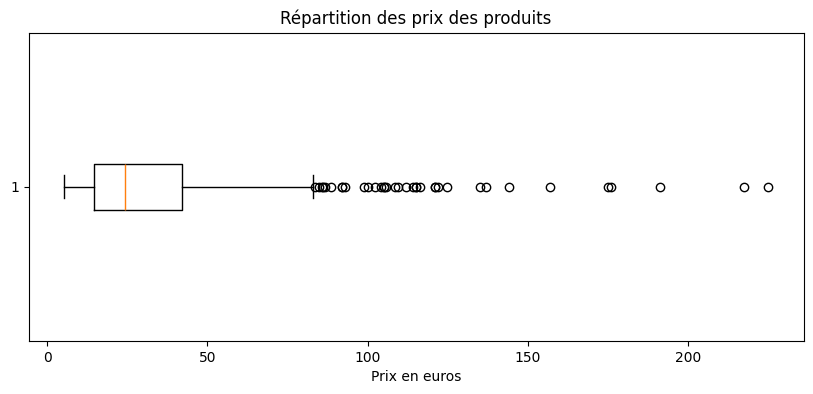

In [ ]:
# Création d'une boîte à moustache horizontale de la répartition des prix
plt.figure(figsize=(10, 4))

plt.boxplot(df_final["price"].dropna(), vert=False)

plt.title("Répartition des prix des produits")
plt.xlabel("Prix en euros")

plt.show()

### Première visualisation de la répartition des prix

La boîte à moustache horizontale permet d'observer la distribution des prix du catalogue.

Ce graphique complète les contrôles chiffrés en donnant une lecture visuelle de la dispersion des prix.  
Il permet notamment d'identifier rapidement les produits dont le prix est particulièrement élevé par rapport au reste du catalogue.

Ces valeurs extrêmes ne sont pas automatiquement des erreurs : elles peuvent correspondre à des produits haut de gamme.

Une analyse statistique complémentaire est nécessaire pour identifier précisément les valeurs atypiques.

In [ ]:
# Autre méthode avec plotly express

fig = px.box(
    df_final,
    x="price",
    title="Répartition des prix des produits"
)

fig.update_layout(
    xaxis_title="Prix en euros"
)

fig.show()

### Visualisation interactive de la répartition des prix

La boîte à moustache réalisée avec Plotly permet d'observer la distribution des prix de manière interactive.

La majorité des produits se situe dans une plage de prix relativement basse, tandis que plusieurs produits apparaissent au-dessus de la borne supérieure de la boîte à moustache.

Ces valeurs élevées peuvent être considérées comme des valeurs atypiques potentielles.  
Cependant, elles ne sont pas automatiquement des erreurs : elles peuvent correspondre à des produits haut de gamme.

Une analyse statistique complémentaire est donc nécessaire pour identifier précisément les outliers.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - Exploration par l'utilisation de méthodes statistiques</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.1 - Identification par le Z-index</h3>
</div>

In [ ]:
# Calculer la moyenne du prix
moyenne_prix = df_final["price"].mean()

# Calculer l'écart-type du prix
ecart_type_prix = df_final["price"].std()

# Calculer le Z-score
df_final["z_score_price"] = (df_final["price"] - moyenne_prix) / ecart_type_prix

print(f"Prix moyen : {moyenne_prix:.2f} €")
print(f"Écart-type du prix : {ecart_type_prix:.2f} €")

display(
    df_final[["product_id", "price", "z_score_price"]]
    .head()
    .round({"price": 2, "z_score_price": 2})
)

Prix moyen : 32.28 €
Écart-type du prix : 26.60 €


,product_id,price,z_score_price
0,3847,24.2,-0.30
1,3849,34.3,0.08
2,3850,20.8,-0.43
3,4032,14.1,-0.68
4,4039,46.0,0.52


In [ ]:
# Calculer le seuil de prix à partir duquel le Z-score est supérieur à 3
seuil_zscore_3 = moyenne_prix + 3 * ecart_type_prix

print(f"Seuil de prix pour un Z-score supérieur à 3 : {seuil_zscore_3:.2f} €")

# Afficher les produits dont le prix dépasse ce seuil
df_outliers_zscore_3 = df_final[df_final["z_score_price"] > 3].sort_values("price", ascending=False)

print(f"Nombre de produits avec un Z-score supérieur à 3 : {df_outliers_zscore_3.shape[0]}")

display(
    df_outliers_zscore_3[["product_id", "id_web", "post_title", "price", "z_score_price"]]
    .round({"price": 2, "z_score_price": 2})
)

Seuil de prix pour un Z-score supérieur à 3 : 112.09 €
Nombre de produits avec un Z-score supérieur à 3 : 17


,product_id,id_web,post_title,price,z_score_price
208,4352,15940,Champagne Egly-Ouriet Grand Cru Millésimé 2008,225.0,7.24
460,5001,14581,David Duband Charmes-Chambertin Grand Cru 2014,217.5,6.96
635,5892,14983,Coteaux Champenois Egly-Ouriet Ambonnay Rouge 2016,191.3,5.98
227,4402,3510,Cognac Frapin VIP XO,176.0,5.40
598,5767,15185,Camille Giroud Clos de Vougeot 2016,175.0,5.36
230,4406,7819,Cognac Frapin Château de Fontpinot 1989 20 Ans d'Age,157.0,4.69
242,4594,None,NaN,144.0,4.20
411,4904,14220,Domaine Des Croix Corton Charlemagne Grand Cru 2016,137.0,3.94
697,6126,14923,Champagne Gosset Célébris Vintage 2007,135.0,3.86
556,5612,14915,Domaine Weinbach Gewurztraminer Grand Cru Furstentum SGN 2010 1/2,124.8,3.48


### Identification des prix atypiques avec le Z-score

La méthode du Z-score permet d’identifier les prix qui s’éloignent fortement de la moyenne du catalogue.

Pour chaque produit, un Z-score est calculé à partir de son prix, de la moyenne des prix et de l’écart-type.

Un seuil de Z-score supérieur à 3 est utilisé pour repérer les prix particulièrement élevés.

Les produits dépassant ce seuil sont considérés comme des valeurs atypiques potentielles.  
Ils ne sont pas automatiquement des erreurs : ils peuvent correspondre à des produits haut de gamme.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.2 - Identification par l'intervalle interquartile</h3>
</div>

In [ ]:
# Utilisation de la fonction "describe" de Pandas pour l'étude des mesures de dispersion
display(df_final["price"].describe().round(2))

count    825.00
mean      32.28
std       26.60
min        5.20
25%       14.50
50%       24.30
75%       42.00
max      225.00
Name: price, dtype: float64

### Analyse descriptive de la variable `price`

La fonction `.describe()` permet d'obtenir un résumé statistique de la colonne `price`.

Elle affiche automatiquement le nombre de valeurs renseignées, la moyenne, l’écart-type, les quartiles, le minimum et le maximum.

Ces indicateurs permettent d’observer la dispersion des prix et de repérer si certains produits semblent nettement plus chers que la majorité du catalogue.

Les valeurs élevées devront ensuite être étudiées plus précisément avec la méthode de l'intervalle interquartile.

In [ ]:
# Définir un seuil pour les articles "outliers" en prix

Q1 = df_final["price"].quantile(0.25)
Q3 = df_final["price"].quantile(0.75)

IQR = Q3 - Q1

seuil_bas = Q1 - 1.5 * IQR
seuil_haut = Q3 + 1.5 * IQR

print(f"Q1 : {Q1:.2f} €")
print(f"Q3 : {Q3:.2f} €")
print(f"Intervalle interquartile : {IQR:.2f} €")
print(f"Seuil bas : {seuil_bas:.2f} €")
print(f"Seuil haut : {seuil_haut:.2f} €")

Q1 : 14.50 €
Q3 : 42.00 €
Intervalle interquartile : 27.50 €
Seuil bas : -26.75 €
Seuil haut : 83.25 €


### Définition du seuil des outliers avec l'intervalle interquartile

La méthode de l'intervalle interquartile permet de définir un seuil statistique pour détecter les prix atypiques.

Le premier quartile `Q1`, le troisième quartile `Q3`, l’intervalle interquartile, le seuil bas et le seuil haut sont calculés automatiquement dans la cellule de code.

Dans ce contexte, le seuil bas peut être peu exploitable si la valeur calculée est négative, car un prix ne peut pas être inférieur à zéro.

Les produits dont le prix dépasse le seuil haut calculé sont considérés comme des outliers potentiels en prix.

In [ ]:
# Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"

df_outliers_iqr = df_final[
    (df_final["price"] < seuil_bas) | (df_final["price"] > seuil_haut)
].copy()

nb_outliers_iqr = df_outliers_iqr.shape[0]

proportion_outliers_iqr = nb_outliers_iqr / df_final.shape[0] * 100

print(f"Nombre d'articles outliers : {nb_outliers_iqr}")
print(f"Proportion d'outliers dans le catalogue : {proportion_outliers_iqr:.2f} %")

display(
    df_outliers_iqr[["product_id", "id_web", "post_title", "price"]]
    .sort_values("price", ascending=False)
    .round({"price": 2})
)

Nombre d'articles outliers : 36
Proportion d'outliers dans le catalogue : 4.36 %


,product_id,id_web,post_title,price
208,4352,15940,Champagne Egly-Ouriet Grand Cru Millésimé 2008,225.0
460,5001,14581,David Duband Charmes-Chambertin Grand Cru 2014,217.5
635,5892,14983,Coteaux Champenois Egly-Ouriet Ambonnay Rouge 2016,191.3
227,4402,3510,Cognac Frapin VIP XO,176.0
598,5767,15185,Camille Giroud Clos de Vougeot 2016,175.0
230,4406,7819,Cognac Frapin Château de Fontpinot 1989 20 Ans d'Age,157.0
242,4594,None,NaN,144.0
411,4904,14220,Domaine Des Croix Corton Charlemagne Grand Cru 2016,137.0
697,6126,14923,Champagne Gosset Célébris Vintage 2007,135.0
556,5612,14915,Domaine Weinbach Gewurztraminer Grand Cru Furstentum SGN 2010 1/2,124.8


### Nombre et proportion d'outliers en prix

La méthode de l'intervalle interquartile permet d'identifier automatiquement les produits considérés comme outliers en prix.

Le nombre d'articles concernés et leur proportion dans le catalogue sont calculés dans la cellule de code.

Cette analyse permet d’évaluer si les prix élevés concernent une minorité de produits ou une partie importante du catalogue.

#### Selon vous, ces outliers sont-ils justifiés ? Comment le démontrer si cela est possible ?
 Justification des outliers en prix

Les outliers détectés ne sont pas automatiquement des erreurs de saisie.

En observant les produits concernés, plusieurs prix élevés correspondent à des produits haut de gamme : champagnes, cognacs, grands crus ou whiskies rares.

Ces produits peuvent naturellement avoir des prix plus élevés que le reste du catalogue.  
Il est donc probable qu'une partie des outliers soit justifiée par la nature des produits vendus.

Pour le démontrer, il faut croiser l'analyse statistique avec le contexte métier, notamment le nom du produit, le type de produit et éventuellement les informations commerciales disponibles.

Cependant, certains outliers doivent rester sous surveillance, notamment les produits ayant un prix élevé mais aucune correspondance web ou aucun nom de produit renseigné. Ces cas peuvent révéler une anomalie de jointure ou une donnée incomplète.

### Vérification ponctuelle des prix concurrents

Afin de compléter l'analyse des prix atypiques, je réalise une vérification ponctuelle sur quelques produits présentant des prix élevés.

Cette vérification ne remplace pas une étude de marché complète.  
Elle donne simplement un premier repère sur le positionnement tarifaire de Bottleneck par rapport à des références externes observées au moment de l'analyse.

Les prix concurrents étant susceptibles d'évoluer, cette comparaison doit être actualisée si le notebook est réutilisé ultérieurement.

Sources consultées pour cette vérification ponctuelle :

- Enosearcher / Comptoir des Millésimes pour le Champagne Egly-Ouriet Grand Cru Millésimé 2008 ;
- iDealwine pour la cote du David Duband Charmes-Chambertin Grand Cru 2014.

In [ ]:
# Comparaison ponctuelle avec des références externes
# Les prix concurrents ci-dessous ont été relevés manuellement et doivent être actualisés si besoin.

df_prix_concurrents = pd.DataFrame({
    "post_title": [
        "Champagne Egly-Ouriet Grand Cru Millésimé 2008",
        "David Duband Charmes-Chambertin Grand Cru 2014"
    ],
    "prix_concurrent_observe": [
        710.00,
        188.00
    ],
    "source_observation": [
        "Enosearcher / Comptoir des Millésimes",
        "iDealwine - cote actuelle"
    ]
})

df_comparaison_concurrence = pd.merge(
    df_prix_concurrents,
    df_final[["post_title", "price"]].rename(columns={"price": "prix_bottleneck"}),
    on="post_title",
    how="left"
)

df_comparaison_concurrence["ecart_euros"] = (
    df_comparaison_concurrence["prix_bottleneck"] 
    - df_comparaison_concurrence["prix_concurrent_observe"]
)

df_comparaison_concurrence["ecart_pourcentage"] = (
    df_comparaison_concurrence["ecart_euros"] 
    / df_comparaison_concurrence["prix_concurrent_observe"] 
    * 100
)

display(
    df_comparaison_concurrence[
        [
            "post_title",
            "prix_bottleneck",
            "prix_concurrent_observe",
            "ecart_euros",
            "ecart_pourcentage",
            "source_observation"
        ]
    ].round({
        "prix_bottleneck": 2,
        "prix_concurrent_observe": 2,
        "ecart_euros": 2,
        "ecart_pourcentage": 2
    })
)

,post_title,prix_bottleneck,prix_concurrent_observe,ecart_euros,ecart_pourcentage,source_observation
0,Champagne Egly-Ouriet Grand Cru Millésimé 2008,225.0,710.0,-485.0,-68.31,Enosearcher / Comptoir des Millésimes
1,David Duband Charmes-Chambertin Grand Cru 2014,217.5,188.0,29.5,15.69,iDealwine - cote actuelle


#### Lecture de la comparaison

Cette vérification ponctuelle permet de remettre certains prix élevés dans leur contexte.  
Lorsqu'un produit Bottleneck est proche ou inférieur aux références externes observées, son prix atypique peut être cohérent avec un positionnement haut de gamme.

À l'inverse, un écart important devrait être analysé plus précisément avant toute décision commerciale.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse univariée du CA, des quantités vendues, des stocks et de la marge ainsi qu'une analyse multivariée  </h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Analyse des ventes en CA</h3>
</div>

In [ ]:
##############################
# Calculer le CA du site web #
##############################

# Créer une colonne calculant le CA par article
df_analyse["ca_par_article"] = df_analyse["price"] * df_analyse["total_sales"]

# Calculer la somme de la colonne "ca_par_article"
ca_total_site_web = df_analyse["ca_par_article"].sum()

# Afficher le chiffre d'affaires total du site web
print(f"Chiffre d'affaires total du site web : {ca_total_site_web:.2f} €")

# Afficher les premières lignes pour vérifier le calcul
display(
    df_analyse[["product_id", "post_title", "price", "total_sales", "ca_par_article"]]
    .head()
    .round({"price": 2, "total_sales": 0, "ca_par_article": 2})
)

Chiffre d'affaires total du site web : 143680.10 €


,product_id,post_title,price,total_sales,ca_par_article
0,3847,Pierre Jean Villa Saint-Joseph Préface 2018,24.2,6.0,145.2
1,3849,Pierre Jean Villa Saint-Joseph Rouge Tildé 2017,34.3,9.0,308.7
2,3850,Pierre Jean Villa Crozes-Hermitage Accroche Coeur 2018,20.8,0.0,0.0
3,4032,Pierre Jean Villa IGP Collines Rhodaniennes Gamine 2018,14.1,12.0,169.2
4,4039,Pierre Jean Villa Côte Rôtie Carmina 2017,46.0,3.0,138.0


### Calcul du chiffre d'affaires du site web

Le chiffre d'affaires par article a été calculé en multipliant le prix de vente du produit par le nombre d'unités vendues.

La formule utilisée est :

`CA par article = prix × quantité vendue`

La somme de tous les chiffres d'affaires par article permet d'obtenir le chiffre d'affaires total du site web.

Ce calcul est réalisé sur le dataframe `df_analyse`, qui contient uniquement les produits ayant une correspondance avec le fichier web.

In [ ]:
###############################
# Palmarès des articles en CA #
###############################

# Effectuer le tri dans l'ordre décroissant du CA
df_palmares_ca = df_analyse.sort_values(
    by="ca_par_article",
    ascending=False
)

# Réinitialiser l'index du dataset
df_palmares_ca = df_palmares_ca.reset_index(drop=True)

# Afficher les 20 premiers articles en CA
top_20_ca = df_palmares_ca.head(TOP_N)

display(
    top_20_ca[[
        "product_id",
        "post_title",
        "price",
        "total_sales",
        "ca_par_article"
    ]].round({"price": 2, "total_sales": 0, "ca_par_article": 2})
)

,product_id,post_title,price,total_sales,ca_par_article
0,4352,Champagne Egly-Ouriet Grand Cru Millésimé 2008,225.0,11.0,2475.0
1,5892,Coteaux Champenois Egly-Ouriet Ambonnay Rouge 2016,191.3,6.0,1147.8
2,4353,Champagne Egly-Ouriet Grand Cru Brut Rosé,79.5,14.0,1113.0
3,5826,Agnès Levet Côte Rôtie Améthyste 2017,41.2,20.0,824.0
4,6212,Domaine des Comtes Lafon Volnay 1er Cru Santenots du Milieu 2015,115.0,7.0,805.0
5,5026,Champagne Agrapart &amp; Fils Minéral Extra Brut Blanc de Blancs Grand Cru 2012,86.8,9.0,781.2
6,5008,Domaine des Comtes Lafon Volnay 1er Cru Santenots du Milieu 2013,105.0,7.0,735.0
7,5767,Camille Giroud Clos de Vougeot 2016,175.0,4.0,700.0
8,6126,Champagne Gosset Célébris Vintage 2007,135.0,5.0,675.0
9,5025,Champagne Agrapart &amp; Fils L'Avizoise Extra Brut Blanc de Blancs Grand Cru 2012,112.0,6.0,672.0


In [ ]:
# Graphique en barre des premiers articles avec plotly express

fig = px.bar(
    top_20_ca,
    x="post_title",
    y="ca_par_article",
    title=f"Top {TOP_N} des articles par chiffre d'affaires",
    labels={
        "post_title": "Produit",
        "ca_par_article": "Chiffre d'affaires"
    },
    hover_data=["product_id", "price", "total_sales"]
)

fig.update_layout(
    xaxis_tickangle=-45
)

fig.show()

### Palmarès des articles en chiffre d'affaires

Les articles ont été triés par chiffre d'affaires décroissant afin d'identifier les produits qui contribuent le plus aux ventes du site web.

Le chiffre d'affaires par article est calculé avec la formule :

`CA par article = prix × quantité vendue`

Le classement des meilleurs produits permet de mettre en évidence les références les plus importantes pour l'activité commerciale.

Cette analyse est utile pour identifier les produits stratégiques, suivre les meilleures ventes et orienter les décisions commerciales.

In [ ]:
#############################
# Calculer le 20 / 80 en CA #
#############################

# Trier les articles par chiffre d'affaires décroissant
df_20_80_ca = df_analyse.sort_values(
    by="ca_par_article",
    ascending=False
).reset_index(drop=True)

# Créer une colonne calculant la part en CA de chaque article dans le CA total
df_20_80_ca["part_ca"] = df_20_80_ca["ca_par_article"] / df_20_80_ca["ca_par_article"].sum()

# Créer une colonne réalisant la somme cumulative de la part de CA
df_20_80_ca["part_ca_cumulee"] = df_20_80_ca["part_ca"].cumsum()

# Calculer le nombre d'articles nécessaires pour représenter 80% du CA
nb_articles_80_ca = df_20_80_ca[df_20_80_ca["part_ca_cumulee"] <= 0.80].shape[0] + 1

# Calculer la proportion que représente ce groupe d'articles dans le catalogue
proportion_articles_80_ca = nb_articles_80_ca / df_20_80_ca.shape[0] * 100

print("Nombre d'articles représentant environ 80% du CA :", nb_articles_80_ca)
print("Proportion du catalogue représentée :", round(proportion_articles_80_ca, 2), "%")

# Afficher les articles concernés
display(df_20_80_ca.head(nb_articles_80_ca)[[
    "product_id",
    "post_title",
    "price",
    "total_sales",
    "ca_par_article",
    "part_ca",
    "part_ca_cumulee"
]])

Nombre d'articles représentant environ 80% du CA : 435
Proportion du catalogue représentée : 60.92 %


,product_id,post_title,price,total_sales,ca_par_article,part_ca,part_ca_cumulee
0,4352,Champagne Egly-Ouriet Grand Cru Millésimé 2008,225.0,11.0,2475.0,0.017226,0.017226
1,5892,Coteaux Champenois Egly-Ouriet Ambonnay Rouge 2016,191.3,6.0,1147.8,0.007989,0.025214
2,4353,Champagne Egly-Ouriet Grand Cru Brut Rosé,79.5,14.0,1113.0,0.007746,0.032961
3,5826,Agnès Levet Côte Rôtie Améthyste 2017,41.2,20.0,824.0,0.005735,0.038696
4,6212,Domaine des Comtes Lafon Volnay 1er Cru Santenots du Milieu 2015,115.0,7.0,805.0,0.005603,0.044298
...,...,...,...,...,...,...,...
430,4664,La Cotelleraie Saint-Nicolas-de-Bourgueil Le Vau Jaumier 2016,16.4,9.0,147.6,0.001027,0.796766
431,4728,Maurice Schoech Gewurztraminer Vendanges Tardives 2017,29.5,5.0,147.5,0.001027,0.797792
432,4075,Plateau des Chênes Lirac 2015,14.7,10.0,147.0,0.001023,0.798816
433,4865,Mourgues du Grès Costières de Nîmes Capitelles Rosé 2018,9.8,15.0,147.0,0.001023,0.799839


### Analyse 20/80 du chiffre d'affaires

L'analyse 20/80 permet d'identifier la concentration du chiffre d'affaires sur une partie du catalogue.

Les articles ont d'abord été triés par chiffre d'affaires décroissant.  
Une colonne `part_ca` a ensuite été créée afin de calculer la part de chaque article dans le chiffre d'affaires total.

La colonne `part_ca_cumulee` permet de cumuler progressivement ces parts de chiffre d'affaires.

L'objectif est d'identifier le nombre d'articles nécessaires pour atteindre environ 80 % du chiffre d'affaires du site web.

Cette analyse permet de savoir si une petite partie du catalogue génère une grande partie du chiffre d'affaires.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Analyse des ventes en quantité</h3>
</div>

In [ ]:
#####################################
# Palmarès des articles en quantité #
#####################################

# Effectuer le tri dans l'ordre décroissant des quantités vendues
df_palmares_quantite = df_analyse.sort_values(
    by="total_sales",
    ascending=False
)

# Réinitialiser l'index du dataset
df_palmares_quantite = df_palmares_quantite.reset_index(drop=True)

# Afficher les 20 premiers articles en quantité vendue
top_20_quantite = df_palmares_quantite.head(TOP_N)

display(
    top_20_quantite[[
        "product_id",
        "post_title",
        "price",
        "total_sales",
        "ca_par_article"
    ]].round({"price": 2, "total_sales": 0, "ca_par_article": 2})
)

,product_id,post_title,price,total_sales,ca_par_article
0,4867,Château De La Selve IGP Coteaux de l'Ardèche Maguelonne Rosé 2019,9.9,36.0,356.4
1,4203,Mas Laval IGP Pays d'Hérault Les Pampres Blancs 2018,9.9,27.0,267.3
2,4275,I Fabbri Chianti Classico Lamole 2017,14.9,24.0,357.6
3,4647,Bernard Baudry Chinon Rouge La Croix Boissée 2017,28.5,22.0,627.0
4,4726,François Baur Pinot Noir Schlittweg 2017,12.7,22.0,279.4
5,6129,Moulin de Gassac IGP Pays d'Hérault Guilhem Blanc 2017,5.2,20.0,104.0
6,5826,Agnès Levet Côte Rôtie Améthyste 2017,41.2,20.0,824.0
7,4220,Xavier Frissant Touraine Amboise Chenin Les Pierres 2018,11.6,18.0,208.8
8,5778,Maurel Pays d'Oc Merlot 2018,5.8,17.0,98.6
9,5803,Château Tour Haut-Caussan Médoc 2015,17.1,17.0,290.7


In [ ]:
# Graphique en barre des premiers articles en quantité avec plotly express

fig = px.bar(
    top_20_quantite,
    x="post_title",
    y="total_sales",
    title=f"Top {TOP_N} des articles par quantité vendue",
    labels={
        "post_title": "Produit",
        "total_sales": "Quantité vendue"
    },
    hover_data=["product_id", "price", "ca_par_article"]
)

fig.update_layout(
    xaxis_tickangle=-45
)

fig.show()

### Palmarès des articles en quantité vendue

Les articles ont été triés selon la colonne `total_sales`, qui correspond au nombre d'unités vendues sur le site web.

Cette analyse permet d'identifier les produits les plus vendus en volume.

Il est important de distinguer cette analyse du palmarès en chiffre d'affaires : un produit peut être beaucoup vendu en quantité, mais générer un chiffre d'affaires plus faible s'il possède un prix unitaire bas.

À l'inverse, un produit vendu en plus faible quantité peut générer un chiffre d'affaires important si son prix est élevé.

<div style="border: 1px solid #FFD700;" >
<h3 style="margin: auto; padding: 20px; color: #FFD700; ">Etape 5.2.1 - Références responsables de 80 % du nombre de ventes</h3>
</div>


In [ ]:
###############################################
# Calculer le 20 / 80 sur le nombre de ventes #
###############################################

# Regrouper les ventes par référence produit
# Cela permet de compter les ventes au niveau de chaque référence.
df_80_ventes = (
    df_analyse
    .groupby("product_id", as_index=False)
    .agg(
        post_title=("post_title", "first"),
        nombre_ventes=("total_sales", "sum")
    )
    .sort_values("nombre_ventes", ascending=False)
    .reset_index(drop=True)
)

# Calculer le total des ventes
total_nombre_ventes = df_80_ventes["nombre_ventes"].sum()

if total_nombre_ventes == 0:
    print("Aucune vente disponible pour calculer le seuil des 80 %.")
else:
    # Calculer la part de chaque référence dans le nombre total de ventes
    df_80_ventes["part_ventes"] = df_80_ventes["nombre_ventes"] / total_nombre_ventes

    # Calculer la part cumulée des ventes
    df_80_ventes["part_ventes_cumulee"] = df_80_ventes["part_ventes"].cumsum()

    # Identifier le nombre de références nécessaires pour atteindre au moins 80 % des ventes
    nb_references_80_ventes = (df_80_ventes["part_ventes_cumulee"] < 0.80).sum() + 1

    # Conserver les références concernées
    df_references_80_ventes = df_80_ventes.head(nb_references_80_ventes).copy()

    # Calculer la part des références concernées dans le catalogue analysé
    part_references_80_ventes = nb_references_80_ventes / df_80_ventes.shape[0] * 100

    # Calculer la part réelle de ventes représentée par ces références
    part_ventes_reelle = df_references_80_ventes["part_ventes"].sum() * 100

    print(f"Nombre de références responsables d'environ 80 % des ventes : {nb_references_80_ventes}")
    print(f"Part des références concernées : {part_references_80_ventes:.2f} %")
    print(f"Part réelle des ventes représentée : {part_ventes_reelle:.2f} %")

    display(
        df_references_80_ventes[[
            "product_id",
            "post_title",
            "nombre_ventes",
            "part_ventes",
            "part_ventes_cumulee"
        ]].round({
            "part_ventes": 4,
            "part_ventes_cumulee": 4
        })
    )


Nombre de références responsables d'environ 80 % des ventes : 434
Part des références concernées : 60.78 %
Part réelle des ventes représentée : 80.11 %


,product_id,post_title,nombre_ventes,part_ventes,part_ventes_cumulee
0,4867,Château De La Selve IGP Coteaux de l'Ardèche Maguelonne Rosé 2019,36.0,0.0063,0.0063
1,4203,Mas Laval IGP Pays d'Hérault Les Pampres Blancs 2018,27.0,0.0047,0.0110
2,4275,I Fabbri Chianti Classico Lamole 2017,24.0,0.0042,0.0151
3,4647,Bernard Baudry Chinon Rouge La Croix Boissée 2017,22.0,0.0038,0.0190
4,4726,François Baur Pinot Noir Schlittweg 2017,22.0,0.0038,0.0228
...,...,...,...,...,...
429,4799,Domaine de la Monardière Vacqueyras Les Deux Monardes 2017,7.0,0.0012,0.7962
430,4201,Mas de Daumas Gassac IGP Saint-Guilhem-le-Désert 2018,7.0,0.0012,0.7974
431,5696,Planeta Sicilia Etna Bianco 2018,7.0,0.0012,0.7986
432,4924,Cave de Castelmaure Corbières Rouge Grande Cuvée 2017,7.0,0.0012,0.7999


In [ ]:
#############################
# Calculer le 20 / 80 en CA #
#############################

# Trier les articles par chiffre d'affaires décroissant
df_20_80_ca = df_analyse.sort_values(
    by="ca_par_article",
    ascending=False
).reset_index(drop=True)

# Créer une colonne calculant la part en CA de chaque ligne dans le dataset
df_20_80_ca["part_ca"] = df_20_80_ca["ca_par_article"] / df_20_80_ca["ca_par_article"].sum()

# Créer une colonne réalisant la somme cumulative de la colonne précédemment créée
df_20_80_ca["part_ca_cumulee"] = df_20_80_ca["part_ca"].cumsum()

# Calculer le nombre d'articles représentant environ 80% du CA
index_80_ca = df_20_80_ca[df_20_80_ca["part_ca_cumulee"] >= 0.80].index[0]
nb_articles_80_ca = index_80_ca + 1

# Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web
proportion_articles_80_ca = nb_articles_80_ca / df_20_80_ca.shape[0] * 100

print("Nombre d'articles représentant environ 80% du CA :", nb_articles_80_ca)
print("Proportion du catalogue représentée :", round(proportion_articles_80_ca, 2), "%")

# Afficher les articles concernés
display(df_20_80_ca.head(nb_articles_80_ca)[[
    "product_id",
    "post_title",
    "price",
    "total_sales",
    "ca_par_article",
    "part_ca",
    "part_ca_cumulee"
]])


Nombre d'articles représentant environ 80% du CA : 435
Proportion du catalogue représentée : 60.92 %


,product_id,post_title,price,total_sales,ca_par_article,part_ca,part_ca_cumulee
0,4352,Champagne Egly-Ouriet Grand Cru Millésimé 2008,225.0,11.0,2475.0,0.017226,0.017226
1,5892,Coteaux Champenois Egly-Ouriet Ambonnay Rouge 2016,191.3,6.0,1147.8,0.007989,0.025214
2,4353,Champagne Egly-Ouriet Grand Cru Brut Rosé,79.5,14.0,1113.0,0.007746,0.032961
3,5826,Agnès Levet Côte Rôtie Améthyste 2017,41.2,20.0,824.0,0.005735,0.038696
4,6212,Domaine des Comtes Lafon Volnay 1er Cru Santenots du Milieu 2015,115.0,7.0,805.0,0.005603,0.044298
...,...,...,...,...,...,...,...
430,4664,La Cotelleraie Saint-Nicolas-de-Bourgueil Le Vau Jaumier 2016,16.4,9.0,147.6,0.001027,0.796766
431,4728,Maurice Schoech Gewurztraminer Vendanges Tardives 2017,29.5,5.0,147.5,0.001027,0.797792
432,4075,Plateau des Chênes Lirac 2015,14.7,10.0,147.0,0.001023,0.798816
433,4865,Mourgues du Grès Costières de Nîmes Capitelles Rosé 2018,9.8,15.0,147.0,0.001023,0.799839


### Analyse 20/80 du chiffre d'affaires

L'analyse 20/80 permet d'étudier la concentration du chiffre d'affaires sur une partie du catalogue.

Les articles ont été triés par chiffre d'affaires décroissant.  
Une colonne `part_ca` a été créée afin de calculer la contribution de chaque article au chiffre d'affaires total.

Une colonne `part_ca_cumulee` a ensuite été ajoutée pour cumuler progressivement ces contributions.

Cette analyse permet d'identifier combien d'articles sont nécessaires pour représenter environ 80 % du chiffre d'affaires du site web.

Si une faible proportion d'articles génère 80 % du chiffre d'affaires, cela signifie que l'activité commerciale est fortement concentrée sur quelques références clés.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Analyse des stocks</h3>
</div>

In [ ]:
######################################
# Calculer le nombre de mois de stock #
######################################

# Création de la colonne nombre de mois de stock
df_analyse["mois_de_stock"] = df_analyse["stock_quantity"] / df_analyse["total_sales"]

# Remplacement des valeurs infinies par 0
df_analyse["mois_de_stock"] = df_analyse["mois_de_stock"].replace([np.inf, -np.inf], 0)

# Remplacement des valeurs manquantes par 0
df_analyse["mois_de_stock"] = df_analyse["mois_de_stock"].fillna(0)

# Effectuer le tri dans l'ordre décroissant du nombre de mois de stock
df_flop_stock = df_analyse.sort_values(
    by="mois_de_stock",
    ascending=False
).reset_index(drop=True)

# Afficher le flop des produits qui ont le plus de mois de stock
flop_20_stock = df_flop_stock.head(TOP_N)

display(
    flop_20_stock[[
        "product_id",
        "post_title",
        "stock_quantity",
        "total_sales",
        "mois_de_stock"
    ]].round({"stock_quantity": 0, "total_sales": 0, "mois_de_stock": 2})
)

,product_id,post_title,stock_quantity,total_sales,mois_de_stock
0,4142,Champagne Gosset Grand Millésime 2006,125,4.0,31.25
1,6126,Champagne Gosset Célébris Vintage 2007,138,5.0,27.60
2,4356,Champagne Egly-Ouriet Premier Cru Les Vignes de Vrigny,81,3.0,27.00
3,4348,Champagne Egly-Ouriet Grand Cru Brut Tradition,125,5.0,25.00
4,4148,Champagne Mailly Grand Cru Brut Rosé,71,3.0,23.67
5,4357,Champagne Larmandier-Bernier Latitude,115,5.0,23.00
6,4144,Champagne Gosset Grand Rosé,91,4.0,22.75
7,5025,Champagne Agrapart &amp; Fils L'Avizoise Extra Brut Blanc de Blancs Grand Cru 2012,136,6.0,22.67
8,4350,Champagne Egly-Ouriet Grand Cru Extra Brut V.P.,145,7.0,20.71
9,4150,Champagne Mailly Grand Cru Intemporelle 2010,123,6.0,20.50


In [ ]:
# Graphique en barre des produits qui ont le plus de mois de stock

fig = px.bar(
    flop_20_stock,
    x="mois_de_stock",
    y="post_title",
    orientation="h",
    title=f"Flop {TOP_N} des produits avec le plus de mois de stock",
    labels={
        "mois_de_stock": "Nombre de mois de stock",
        "post_title": "Produit"
    },
    hover_data=["product_id", "stock_quantity", "total_sales"]
)

fig.update_layout(
    yaxis={"categoryorder": "total ascending"}
)

fig.show()

### Analyse du nombre de mois de stock

Le nombre de mois de stock permet d'estimer combien de temps le stock actuel pourrait durer au rythme des ventes observées.

La formule utilisée est :

`mois de stock = stock disponible / ventes mensuelles`

Les produits ont ensuite été triés dans l'ordre décroissant afin d'identifier ceux qui possèdent le plus grand nombre de mois de stock.

Ces produits peuvent représenter un risque d'immobilisation de stock : ils disposent d'un stock important par rapport à leur niveau de ventes.

Cette analyse permet donc d'identifier les références à surveiller, notamment les produits qui se vendent peu mais occupent une place importante dans le stock.

In [ ]:
####################################
# Valorisation des stocks en euros #
####################################

# Création de la colonne Valorisation des stocks en euros
df_final["Valorisation_stock_euros"] = df_final["stock_quantity"] * df_final["purchase_price"]

# Calculer la somme de la colonne "Valorisation_stock_euros"
valorisation_totale_stock = df_final["Valorisation_stock_euros"].sum()

print("Valorisation totale du stock :", round(valorisation_totale_stock, 2), "€")

# Afficher les premières lignes pour vérifier le calcul
display(df_final[[
    "product_id",
    "price",
    "purchase_price",
    "stock_quantity",
    "Valorisation_stock_euros"
]].head())

Valorisation totale du stock : 298627.66 €


,product_id,price,purchase_price,stock_quantity,Valorisation_stock_euros
0,3847,24.2,12.88,16,206.08
1,3849,34.3,17.54,10,175.40
2,3850,20.8,10.64,0,0.00
3,4032,14.1,6.92,26,179.92
4,4039,46.0,23.77,3,71.31


### Valorisation des stocks en euros

La valorisation du stock a été calculée en multipliant la quantité disponible en stock par le prix d'achat du produit.

La formule utilisée est :

`Valorisation du stock = stock_quantity × purchase_price`

Cette analyse permet d'estimer la valeur financière immobilisée dans les stocks.

La somme de la colonne `Valorisation_stock_euros` donne la valorisation totale du stock disponible.

In [ ]:
##############################################
# Valorisation du nombre de produits en stock #
##############################################

# Calculer la somme de la colonne stock_quantity
nombre_total_produits_stock = df_final["stock_quantity"].sum()

print(f"Nombre total de produits en stock : {nombre_total_produits_stock:.0f}")

Nombre total de produits en stock : 17822


### Nombre total de produits en stock

Le nombre total de produits en stock est calculé en additionnant toutes les valeurs de la colonne `stock_quantity`.

Cette mesure permet d'obtenir le volume total d'unités disponibles dans le stock.

Contrairement à la valorisation du stock en euros, ce calcul ne prend pas en compte le prix d'achat : il mesure uniquement le nombre d'unités physiques disponibles.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse du taux de marge</h3>
</div>

In [ ]:
############################
# Analyse du taux de marge #
############################

# Création de la colonne Prix HT
df_final["prix_ht"] = df_final["price"] / (1 + TAUX_TVA)

# Création de la colonne Taux de marge
df_final["taux_marge"] = (df_final["prix_ht"] - df_final["purchase_price"]) / df_final["purchase_price"]

# Afficher le minimum de la colonne "taux_marge"
print(f"Taux de marge minimum : {df_final['taux_marge'].min():.2%}")

# Afficher le maximum de la colonne "taux_marge"
print(f"Taux de marge maximum : {df_final['taux_marge'].max():.2%}")

# Afficher les premières lignes pour vérifier le calcul
display(
    df_final[[
        "product_id",
        "price",
        "prix_ht",
        "purchase_price",
        "taux_marge"
    ]]
    .head()
    .round({"price": 2, "prix_ht": 2, "purchase_price": 2, "taux_marge": 4})
)

Taux de marge minimum : -86.39%
Taux de marge maximum : 91.41%


,product_id,price,prix_ht,purchase_price,taux_marge
0,3847,24.2,20.17,12.88,0.5657
1,3849,34.3,28.58,17.54,0.6296
2,3850,20.8,17.33,10.64,0.6291
3,4032,14.1,11.75,6.92,0.6980
4,4039,46.0,38.33,23.77,0.6127


### Analyse du taux de marge

Le prix HT a été calculé à partir du prix de vente TTC en divisant la colonne `price` par `1,20`.

Le taux de marge a ensuite été calculé avec la formule suivante :

`Taux de marge = (Prix HT - Prix d'achat) / Prix d'achat`

Cette analyse permet de mesurer la rentabilité des produits du catalogue.

Le taux de marge minimum et le taux de marge maximum permettent d'identifier les produits les moins rentables et les produits les plus rentables.

In [ ]:
# Affichage des lignes avec un taux de marge inférieur à 0

df_marge_negative = df_final[df_final["taux_marge"] < 0]

print(f"Nombre de produits avec un taux de marge négatif : {df_marge_negative.shape[0]}")

display(
    df_marge_negative[[
        "product_id",
        "id_web",
        "post_title",
        "price",
        "prix_ht",
        "purchase_price",
        "taux_marge"
    ]]
    .round({"price": 2, "prix_ht": 2, "purchase_price": 2, "taux_marge": 4})
)

Nombre de produits avec un taux de marge négatif : 4


,product_id,id_web,post_title,price,prix_ht,purchase_price,taux_marge
210,4355,12589,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,12.65,10.54,77.48,-0.8639
391,4864,15154,NaN,8.30,6.92,9.99,-0.3076
724,6324,None,NaN,92.00,76.67,99.00,-0.2256
817,7196,None,NaN,31.00,25.83,31.20,-0.1720


### Analyse des taux de marge négatifs

Les produits dont le taux de marge est inférieur à 0 sont des produits pour lesquels le prix de vente HT est inférieur au prix d'achat.

Cela signifie que ces produits sont vendus à perte.

Ces lignes doivent être analysées avec attention, car elles peuvent révéler :
- une erreur de prix de vente ;
- une erreur de prix d'achat ;
- une promotion exceptionnelle ;
- ou une stratégie commerciale volontaire.

Ces produits doivent donc être vérifiés avant de conclure définitivement à une anomalie.

In [ ]:
# Création d'un dataframe avec les taux positifs

df_marge_positive = df_final[df_final["taux_marge"] >= 0].copy()

# Afficher le minimum de la colonne "taux_marge"
print("Taux de marge minimum positif :", round(df_marge_positive["taux_marge"].min() * 100, 2), "%")

# Afficher le maximum de la colonne "taux_marge"
print("Taux de marge maximum positif :", round(df_marge_positive["taux_marge"].max() * 100, 2), "%")

# Afficher les premières lignes pour vérifier
display(df_marge_positive[[
    "product_id",
    "post_title",
    "price",
    "prix_ht",
    "purchase_price",
    "taux_marge"
]].head())


Taux de marge minimum positif : 29.5 %
Taux de marge maximum positif : 91.41 %


,product_id,post_title,price,prix_ht,purchase_price,taux_marge
0,3847,Pierre Jean Villa Saint-Joseph Préface 2018,24.2,20.166667,12.88,0.565735
1,3849,Pierre Jean Villa Saint-Joseph Rouge Tildé 2017,34.3,28.583333,17.54,0.629609
2,3850,Pierre Jean Villa Crozes-Hermitage Accroche Coeur 2018,20.8,17.333333,10.64,0.629073
3,4032,Pierre Jean Villa IGP Collines Rhodaniennes Gamine 2018,14.1,11.750000,6.92,0.697977
4,4039,Pierre Jean Villa Côte Rôtie Carmina 2017,46.0,38.333333,23.77,0.612677


### Analyse des taux de marge positifs

Un dataframe spécifique a été créé afin de conserver uniquement les produits dont le taux de marge est positif ou nul.

Cela permet d'analyser les marges des produits qui ne sont pas vendus à perte.

Le taux de marge minimum positif permet d'identifier les produits les moins rentables parmi les produits encore rentables.

Le taux de marge maximum permet d'identifier les produits avec la marge relative la plus élevée.

In [ ]:
# Vérifier les colonnes disponibles dans df_marge_positive

display(df_marge_positive.columns.tolist())

['product_id',
 'onsale_web',
 'price',
 'stock_quantity',
 'stock_status',
 'purchase_price',
 'verification_stock_status',
 'id_web',
 'merge_erp_liaison',
 'sku',
 'total_sales',
 'average_rating',
 'rating_count',
 'post_title',
 'post_type',
 'post_name',
 'guid',
 'merge_web',
 'z_score_price',
 'Valorisation_stock_euros',
 'prix_ht',
 'taux_marge']

In [ ]:
# Récupérer la colonne product_type depuis le fichier web brut

# Recharger le fichier web complet si nécessaire
try:
    df_web_brut
except NameError:
    df_web_brut = pd.read_excel("web.xlsx")

# Créer un dataframe avec uniquement sku et product_type
df_web_type = df_web_brut.loc[
    df_web_brut["post_type"] == "product",
    ["sku", "product_type"]
].copy()

# Supprimer les lignes sans sku
df_web_type = df_web_type[df_web_type["sku"].notnull()].copy()

# Convertir les identifiants en texte pour sécuriser la jointure
df_web_type["id_web"] = df_web_type["sku"].astype(str)
df_final["id_web"] = df_final["id_web"].astype(str)

# Garder uniquement id_web et product_type
df_web_type = df_web_type[["id_web", "product_type"]]

# Ajouter product_type dans df_final
df_final = df_final.merge(
    df_web_type,
    on="id_web",
    how="left"
)

# Vérifier que product_type est maintenant présent
display(df_final[["product_id", "id_web", "product_type"]].head())

,product_id,id_web,product_type
0,3847,15298,Vin
1,3849,15296,Vin
2,3850,15300,Vin
3,4032,19814,Vin
4,4039,19815,Vin


In [ ]:
# Recréer le dataframe avec les taux de marge positifs après ajout de product_type

df_marge_positive = df_final[df_final["taux_marge"] >= 0].copy()

print("Nombre de produits avec marge positive :", df_marge_positive.shape[0])
print("Colonnes disponibles :", df_marge_positive.columns.tolist())

Nombre de produits avec marge positive : 821
Colonnes disponibles : ['product_id', 'onsale_web', 'price', 'stock_quantity', 'stock_status', 'purchase_price', 'verification_stock_status', 'id_web', 'merge_erp_liaison', 'sku', 'total_sales', 'average_rating', 'rating_count', 'post_title', 'post_type', 'post_name', 'guid', 'merge_web', 'z_score_price', 'Valorisation_stock_euros', 'prix_ht', 'taux_marge', 'product_type']


In [ ]:
# Création d'un dataframe avec le taux de marge moyen par type de produit

df_taux_marge_type = (
    df_marge_positive
    .dropna(subset=["product_type"])
    .groupby("product_type", as_index=False)
    .agg(taux_marge_moyen=("taux_marge", "mean"))
)

# Conversion du taux de marge en pourcentage
df_taux_marge_type["taux_marge_moyen_pourcentage"] = df_taux_marge_type["taux_marge_moyen"] * 100

# Trier du taux de marge moyen le plus élevé au plus faible
df_taux_marge_type = df_taux_marge_type.sort_values(
    by="taux_marge_moyen_pourcentage",
    ascending=False
)

display(
    df_taux_marge_type.round({
        "taux_marge_moyen": 4,
        "taux_marge_moyen_pourcentage": 2
    })
)

,product_type,taux_marge_moyen,taux_marge_moyen_pourcentage
1,Cognac,0.8232,82.32
5,Whisky,0.8174,81.74
2,Gin,0.7483,74.83
4,Vin,0.6150,61.50
0,Champagne,0.3995,39.95
3,Huile d'olive,0.3339,33.39


### Correction de la colonne product_type

L'erreur `KeyError: 'product_type'` indiquait que la colonne `product_type` n'était pas présente dans le dataframe utilisé pour l'analyse des marges.

La colonne a été récupérée depuis le fichier web complet, puis ajoutée au dataframe final grâce à la correspondance entre `id_web` et `sku`.

Après cette correction, il est possible de calculer le taux de marge moyen par type de produit.

In [ ]:
# Affichage dans un graphique du taux de marge par type de produit

import plotly.express as px

fig = px.bar(
    df_taux_marge_type,
    x="product_type",
    y="taux_marge_moyen_pourcentage",
    title="Taux de marge moyen par type de produit",
    labels={
        "product_type": "Type de produit",
        "taux_marge_moyen_pourcentage": "Taux de marge moyen (%)"
    },
    text="taux_marge_moyen_pourcentage"
)

fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig.update_layout(
    xaxis_tickangle=-45,
    yaxis_title="Taux de marge moyen (%)",
    xaxis_title="Type de produit"
)

fig.show()

### Visualisation du taux de marge moyen par type de produit

Le graphique présente le taux de marge moyen pour chaque type de produit.

Cette visualisation permet d’identifier rapidement les catégories les plus rentables et celles dont la marge moyenne est plus faible.

L’analyse par type de produit est utile pour orienter les décisions commerciales, par exemple en mettant en avant les catégories les plus rentables ou en surveillant celles qui présentent une rentabilité plus faible.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.5 - Analyse des corrélations entre les variables stock, sales et price</h3>
</div>

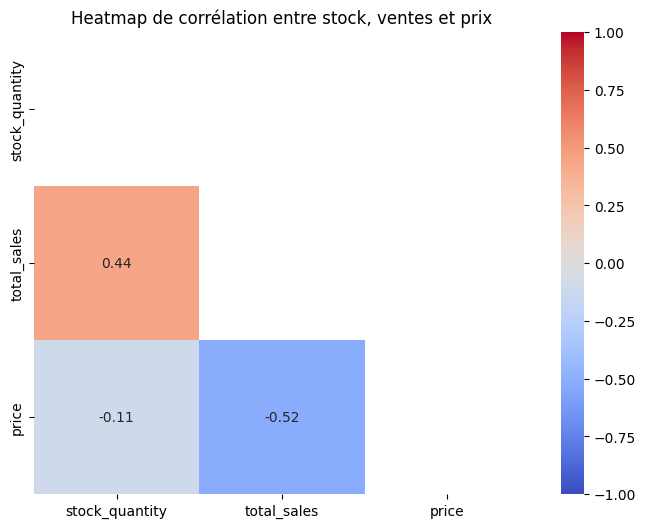

In [ ]:
############################
# Analyse des corrélations #
############################

# Importation de Seaborn
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Sélection des variables à analyser
df_correlation = df_analyse[[
    "stock_quantity",
    "total_sales",
    "price"
]].copy()

# Calcul de la matrice de corrélation
matrice_correlation = df_correlation.corr()

# Création d'un masque pour n'afficher qu'une demi heatmap
mask = np.triu(np.ones_like(matrice_correlation, dtype=bool))

# Création de la heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    matrice_correlation,
    mask=mask,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Heatmap de corrélation entre stock, ventes et prix")
plt.show()

### Analyse des corrélations

La heatmap permet d'observer les corrélations entre les variables `stock_quantity`, `total_sales` et `price`.

Une corrélation proche de `1` indique une relation positive forte entre deux variables.  
Une corrélation proche de `-1` indique une relation négative forte.  
Une corrélation proche de `0` indique qu'il n'y a pas de relation linéaire forte.

Cette analyse permet de vérifier s'il existe un lien entre le prix des produits, les quantités vendues et le stock disponible.

Il faut toutefois rester prudent : une corrélation ne prouve pas une relation de cause à effet. Elle indique seulement que deux variables évoluent ensemble, ou non, de manière linéaire.

### Visualisation complémentaire : stock disponible et ventes

En complément de la heatmap, un nuage de points permet de visualiser plus concrètement la relation entre le stock disponible et les quantités vendues.

Chaque point représente un produit.  
Cette visualisation aide à repérer les produits avec beaucoup de stock mais peu de ventes, ou au contraire les produits avec un bon écoulement.

In [ ]:
fig = px.scatter(
    df_analyse,
    x="stock_quantity",
    y="total_sales",
    hover_data=["product_id", "post_title", "price"],
    title="Relation entre stock disponible et quantités vendues",
    labels={
        "stock_quantity": "Stock disponible",
        "total_sales": "Quantités vendues"
    }
)

fig.show()

### Conclusion sur les corrélations

L'analyse des corrélations entre le stock, les ventes et le prix ne montre pas de relation linéaire forte entre ces variables.

Les corrélations observées sont globalement faibles, ce qui signifie qu'aucune variable ne semble expliquer fortement une autre de manière directe.

La relation entre le prix et les ventes peut être légèrement négative : cela peut indiquer que les produits les plus chers ont tendance à être vendus en plus faibles quantités. Cependant, cette relation reste limitée et ne permet pas de conclure à elle seule que le prix détermine le volume de ventes.

La relation entre le stock et les ventes semble également faible. Un stock important ne signifie donc pas automatiquement qu'un produit se vend beaucoup.

Il faut donc rester prudent dans l'interprétation : une corrélation ne prouve pas une relation de cause à effet. Elle indique seulement si deux variables évoluent ensemble de manière linéaire.

Pour approfondir l'analyse, il serait pertinent de croiser ces résultats avec d'autres éléments comme le type de produit, le niveau de prix, la marge, les ruptures de stock ou la saisonnalité des ventes.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.6 - Mise à disposition de la nouvelle table sur un fichier Excel</h3>
</div>

In [ ]:
# Mettre le dataset final sur un fichier Excel
# Cette étape peut être utile pour partager le résultat du dataset obtenu avec les équipes.

df_final.to_excel("dataset_final_bottleneck.xlsx", index=False)

print("Le fichier Excel a été exporté avec succès.")

Le fichier Excel a été exporté avec succès.


### Export du dataset final

Le dataset final a été exporté au format Excel afin de pouvoir être partagé plus facilement avec les équipes.

Cette étape permet de transmettre un fichier exploitable contenant les données consolidées et les indicateurs calculés durant l'analyse.

L'argument `index=False` permet de ne pas exporter l'index Pandas dans le fichier Excel.

## Perspectives d'amélioration

### Automatisation de la comparaison concurrentielle

Une amélioration possible serait d'automatiser la comparaison des prix avec ceux de concurrents grâce au web scraping.

L'objectif serait de récupérer régulièrement les prix de produits similaires sur des sites concurrents, puis de comparer ces prix avec ceux de Bottleneck.  
Cela permettrait de suivre le positionnement tarifaire, d'identifier les produits potentiellement trop chers ou trop bas, et d'enrichir l'analyse commerciale avec des données externes.

Cette automatisation devrait toutefois respecter les conditions d'utilisation des sites consultés et intégrer des contrôles qualité sur les données récupérées.

### Autres pistes possibles

D'autres améliorations pourraient également être envisagées :

- suivre l'évolution des ventes dans le temps ;
- croiser les ventes avec les niveaux de stock pour mieux anticiper les ruptures ;
- enrichir les données produits avec des informations externes ;
- automatiser l'export du dataset final ;
- mettre en place un tableau de bord de suivi du stock, des ventes et des marges.